In [ ]:
import torch
import soundfile as sf
import torchaudio
import matplotlib.pyplot as plt
from nnAudio.features.gammatone import Gammatonegram

# 1. 파일 경로 설정 (실제 가지고 계신 데이터셋의 wav 파일 경로로 변경하세요)
# 예: DCASE STARSS 데이터셋의 임의의 파일
audio_path = 'C:/data/2024DCASE_data/mic_dev/dev-test-sony/fold4_room23_mix001.wav' 

# 프론트엔드 파라미터 세팅 (기존 코드와 동일)
sr = 24000
n_bins = 64
hop_length = 480
win_length = hop_length * 2
n_fft = 2 ** (win_length - 1).bit_length()
fmax = sr //2

# 2. 오디오 로드 및 전처리
waveform, sample_rate = sf.read(audio_path)
waveform = torch.from_numpy(waveform).transpose(0, 1).float()
# SELD용 4채널(FOA/MIC) 데이터라면, 시각화를 위해 첫 번째 채널만 가져옵니다.
if waveform.shape[0] > 1:
    waveform = waveform[0:1, :]
# 샘플링 레이트 맞추기
if sample_rate != sr:
    waveform = torchaudio.functional.resample(waveform, sample_rate, sr)


# 3. 특징 추출기 초기화 (학습 옵션은 반드시 끄기!)
mel_extractor = torchaudio.transforms.MelSpectrogram(
    sample_rate=sr, n_fft=n_fft, hop_length=hop_length, 
    win_length=win_length, n_mels=n_bins, window_fn=torch.hann_window
)

gt_extractor = Gammatonegram(
    sr=sr, n_fft=n_fft, n_bins=n_bins, hop_length=hop_length, 
    window='hann', fmax=fmax, win_length=win_length, 
    trainable_STFT=False, trainable_bins=False
)

# 4. 특징 추출 및 스케일(Log) 변환
# --- [Log-Mel] ---
mel_spec = mel_extractor(waveform)
mel_log = 10.0 * torch.log10(mel_spec.clamp_min(1e-10))

# --- [Log-Gammatone] ---
gt_spec = gt_extractor(waveform)
# 지난번 해결책이었던 1000배 스케일 업 적용
gt_spec_scaled = gt_spec 
gt_log = 10.0 * torch.log10(gt_spec_scaled.clamp_min(1e-10))
# [1, n_bins, Frames] -> [n_bins, Frames] 로 차원 축소
mel_img = mel_log[0].numpy()
gt_img = gt_log[0].numpy()

# 5. 시각화
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# 색상 맵(Color map)의 범위를 동일하게 맞춰야 정확한 비교가 가능합니다.
vmin = min(mel_img.min(), gt_img.min())
vmax = max(mel_img.max(), gt_img.max())

# Mel Spectrogram
im1 = axes[0].imshow(mel_img, aspect='auto', origin='lower', cmap='magma', vmin=vmin, vmax=vmax)
axes[0].set_title('Log-Mel Spectrogram (torchaudio)', fontsize=14)
axes[0].set_ylabel('Mel Bins')

# Gammatone Spectrogram
im2 = axes[1].imshow(gt_img, aspect='auto', origin='lower', cmap='magma', vmin=vmin, vmax=vmax)
axes[1].set_title('Scaled Log-Gammatone Spectrogram (nnAudio)', fontsize=14)
axes[1].set_ylabel('Gammatone Bins')
axes[1].set_xlabel('Frames (Time)')

# 컬러바 추가 (에너지 크기 확인용)
fig.colorbar(im1, ax=axes[0], format='%+2.0f dB')
fig.colorbar(im2, ax=axes[1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# gt_log: 정규화(Standardization)를 하기 직전, 로그만 씌운 Gammatone 스펙트로그램
# 차원 축소: [1, n_bins, Frames] -> [n_bins, Frames]
data = gt_norm[0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- [방법 1: 히스토그램 (분포와 꼬리 확인)] ---
# 데이터가 어떻게 분포하는지, 극단적으로 큰 값이 있는지 확인합니다.
# 이상치가 적은 픽셀에만 존재할 수 있으므로 y축을 로그 스케일로 봅니다.
axes[0].hist(data.flatten(), bins=100, color='royalblue', alpha=0.7)
axes[0].set_title('1. Histogram of Values (Log Y-scale)')
axes[0].set_yscale('log') 
axes[0].set_xlabel('Value (dB)')
axes[0].set_ylabel('Pixel Count (Log)')

# --- [방법 2: 시간축(Frame) 최댓값 플롯 (패딩 스파이크 확인)] ---
# 각 시간 프레임별로 가장 큰 에너지를 가진 값을 선 그래프로 그립니다.
max_over_time = data.max(axis=0) 
axes[1].plot(max_over_time, color='crimson')
axes[1].set_title('2. Max Value over Time (Frames)')
axes[1].set_xlabel('Frames (Time)')
axes[1].set_ylabel('Max dB')

# --- [방법 3: 주파수축(Bin) 최댓값 플롯 (특정 대역 쏠림 확인)] ---
# 각 주파수 빈(Bin)별로 전체 시간 중 가장 큰 값을 선 그래프로 그립니다.
max_over_freq = data.max(axis=1)
axes[2].plot(max_over_freq, color='seagreen')
axes[2].set_title('3. Max Value over Frequency Bins')
axes[2].set_xlabel('Gammatone Bins (Low -> High)')
axes[2].set_ylabel('Max dB')

plt.tight_layout()
plt.show()

# --- [보너스 방법: 상위 1% 쳐내고 스펙트로그램 그리기 (Percentile Clipping)] ---
# 진짜 이상치 때문에 그림이 망가진 건지 확인하는 결정적 방법입니다.
vmax_99 = np.percentile(data, 99.5) # 상위 0.5%의 값을 최댓값으로 강제 지정
vmin_01 = np.percentile(data, 1.0)  # 하위 1%의 값을 최솟값으로 강제 지정

plt.figure(figsize=(10, 4))
plt.imshow(data, aspect='auto', origin='lower', cmap='magma', vmin=vmin_01, vmax=vmax_99)
plt.title(f'Clipped Spectrogram (vmax={vmax_99:.1f} dB, 99.5th percentile)')
plt.colorbar(format='%+2.0f dB')
plt.ylabel('Gammatone Bins')
plt.xlabel('Frames')
plt.show()

print(f"전체 절댓값 Max: {data.max():.2f}")
print(f"상위 0.5% Max: {vmax_99:.2f}")

In [1]:
import re
import matplotlib.pyplot as plt
from pathlib import Path

log_text = r"""
INFO: 03/28/2026 22:53:46: epoch: 100, step: 27100/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 22:54:12: epoch: 100, step: 27200/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 22:54:38: epoch: 100, step: 27300/100000, lr:0.001000, train_loss:0.0031
INFO: 03/28/2026 22:54:54: epoch: 100, step: 27300/100000, train_time:70.54, test_time:5.46, average_train_loss:0.0029, average_test_loss:0.0364
INFO: 03/28/2026 22:54:54: ER/F/LE/LR/SELD: 0.6166/0.3608/20.8017/0.6228/0.4372
INFO: 03/28/2026 22:54:54: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch100_step27300.pth
INFO: 03/28/2026 22:55:20: epoch: 101, step: 27400/100000, lr:0.001000, train_loss:0.0030
INFO: 03/28/2026 22:55:46: epoch: 101, step: 27500/100000, lr:0.001000, train_loss:0.0030
INFO: 03/28/2026 22:56:23: epoch: 101, step: 27573/100000, train_time:70.63, test_time:6.44, average_train_loss:0.0028, average_test_loss:0.0344
INFO: 03/28/2026 22:56:23: ER/F/LE/LR/SELD: 0.6334/0.3690/20.5001/0.6462/0.4330
INFO: 03/28/2026 22:56:23: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch101_step27573.pth
INFO: 03/28/2026 22:56:30: epoch: 102, step: 27600/100000, lr:0.001000, train_loss:0.0029
INFO: 03/28/2026 22:56:56: epoch: 102, step: 27700/100000, lr:0.001000, train_loss:0.0032
INFO: 03/28/2026 22:57:21: epoch: 102, step: 27800/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 22:57:50: epoch: 102, step: 27846/100000, train_time:70.63, test_time:5.27, average_train_loss:0.0029, average_test_loss:0.0357
INFO: 03/28/2026 22:57:50: ER/F/LE/LR/SELD: 0.6366/0.3521/21.9443/0.6315/0.4437
INFO: 03/28/2026 22:57:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch102_step27846.pth
INFO: 03/28/2026 22:58:04: epoch: 103, step: 27900/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 22:58:30: epoch: 103, step: 28000/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 22:58:55: epoch: 103, step: 28100/100000, lr:0.001000, train_loss:0.0029
INFO: 03/28/2026 22:59:17: epoch: 103, step: 28119/100000, train_time:70.43, test_time:5.39, average_train_loss:0.0031, average_test_loss:0.0345
INFO: 03/28/2026 22:59:17: ER/F/LE/LR/SELD: 0.6363/0.3270/20.5798/0.5624/0.4653
INFO: 03/28/2026 22:59:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch103_step28119.pth
INFO: 03/28/2026 22:59:38: epoch: 104, step: 28200/100000, lr:0.001000, train_loss:0.0038
INFO: 03/28/2026 23:00:05: epoch: 104, step: 28300/100000, lr:0.001000, train_loss:0.0040
INFO: 03/28/2026 23:00:45: epoch: 104, step: 28392/100000, train_time:71.08, test_time:5.25, average_train_loss:0.0040, average_test_loss:0.0358
INFO: 03/28/2026 23:00:45: ER/F/LE/LR/SELD: 0.6500/0.3282/21.1949/0.5975/0.4605
INFO: 03/28/2026 23:00:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch104_step28392.pth
INFO: 03/28/2026 23:00:48: epoch: 105, step: 28400/100000, lr:0.001000, train_loss:0.0048
INFO: 03/28/2026 23:01:14: epoch: 105, step: 28500/100000, lr:0.001000, train_loss:0.0072
INFO: 03/28/2026 23:01:39: epoch: 105, step: 28600/100000, lr:0.001000, train_loss:0.0078
INFO: 03/28/2026 23:02:13: epoch: 105, step: 28665/100000, train_time:70.31, test_time:5.26, average_train_loss:0.0072, average_test_loss:0.0328
INFO: 03/28/2026 23:02:13: ER/F/LE/LR/SELD: 0.6962/0.3022/24.0292/0.6182/0.4773
INFO: 03/28/2026 23:02:13: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch105_step28665.pth
INFO: 03/28/2026 23:02:22: epoch: 106, step: 28700/100000, lr:0.001000, train_loss:0.0066
INFO: 03/28/2026 23:02:48: epoch: 106, step: 28800/100000, lr:0.001000, train_loss:0.0060
INFO: 03/28/2026 23:03:13: epoch: 106, step: 28900/100000, lr:0.001000, train_loss:0.0041
INFO: 03/28/2026 23:03:40: epoch: 106, step: 28938/100000, train_time:70.12, test_time:5.24, average_train_loss:0.0057, average_test_loss:0.0346
INFO: 03/28/2026 23:03:40: ER/F/LE/LR/SELD: 0.6326/0.3522/20.7348/0.6019/0.4484
INFO: 03/28/2026 23:03:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch106_step28938.pth
INFO: 03/28/2026 23:03:56: epoch: 107, step: 29000/100000, lr:0.001000, train_loss:0.0037
INFO: 03/28/2026 23:04:22: epoch: 107, step: 29100/100000, lr:0.001000, train_loss:0.0023
INFO: 03/28/2026 23:04:48: epoch: 107, step: 29200/100000, lr:0.001000, train_loss:0.0033
INFO: 03/28/2026 23:05:07: epoch: 107, step: 29211/100000, train_time:70.81, test_time:5.25, average_train_loss:0.0036, average_test_loss:0.0343
INFO: 03/28/2026 23:05:07: ER/F/LE/LR/SELD: 0.6401/0.3636/20.3296/0.6240/0.4414
INFO: 03/28/2026 23:05:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch107_step29211.pth
INFO: 03/28/2026 23:05:30: epoch: 108, step: 29300/100000, lr:0.001000, train_loss:0.0033
INFO: 03/28/2026 23:05:56: epoch: 108, step: 29400/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 23:06:34: epoch: 108, step: 29484/100000, train_time:70.25, test_time:5.24, average_train_loss:0.0028, average_test_loss:0.0350
INFO: 03/28/2026 23:06:34: ER/F/LE/LR/SELD: 0.6224/0.3584/19.9162/0.6134/0.4403
INFO: 03/28/2026 23:06:35: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch108_step29484.pth
INFO: 03/28/2026 23:06:39: epoch: 109, step: 29500/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 23:07:05: epoch: 109, step: 29600/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:07:30: epoch: 109, step: 29700/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 23:08:01: epoch: 109, step: 29757/100000, train_time:70.32, test_time:5.25, average_train_loss:0.0025, average_test_loss:0.0380
INFO: 03/28/2026 23:08:01: ER/F/LE/LR/SELD: 0.6392/0.3623/21.1311/0.6103/0.4460
INFO: 03/28/2026 23:08:01: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch109_step29757.pth
INFO: 03/28/2026 23:08:13: epoch: 110, step: 29800/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:08:39: epoch: 110, step: 29900/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:09:05: epoch: 110, step: 30000/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 23:09:30: epoch: 110, step: 30030/100000, train_time:71.53, test_time:5.45, average_train_loss:0.0025, average_test_loss:0.0374
INFO: 03/28/2026 23:09:30: ER/F/LE/LR/SELD: 0.6287/0.3587/20.0640/0.6212/0.4401
INFO: 03/28/2026 23:09:30: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch110_step30030.pth
INFO: 03/28/2026 23:09:48: epoch: 111, step: 30100/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:10:14: epoch: 111, step: 30200/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:10:39: epoch: 111, step: 30300/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:10:56: epoch: 111, step: 30303/100000, train_time:70.14, test_time:5.25, average_train_loss:0.0025, average_test_loss:0.0358
INFO: 03/28/2026 23:10:56: ER/F/LE/LR/SELD: 0.6088/0.3741/19.7932/0.6441/0.4251
INFO: 03/28/2026 23:10:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch111_step30303.pth
INFO: 03/28/2026 23:11:22: epoch: 112, step: 30400/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 23:11:47: epoch: 112, step: 30500/100000, lr:0.001000, train_loss:0.0031
INFO: 03/28/2026 23:12:23: epoch: 112, step: 30576/100000, train_time:71.00, test_time:5.25, average_train_loss:0.0026, average_test_loss:0.0368
INFO: 03/28/2026 23:12:23: ER/F/LE/LR/SELD: 0.6323/0.3467/19.9097/0.6032/0.4483
INFO: 03/28/2026 23:12:24: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch112_step30576.pth
INFO: 03/28/2026 23:12:30: epoch: 113, step: 30600/100000, lr:0.001000, train_loss:0.0029
INFO: 03/28/2026 23:12:56: epoch: 113, step: 30700/100000, lr:0.001000, train_loss:0.0039
INFO: 03/28/2026 23:13:21: epoch: 113, step: 30800/100000, lr:0.001000, train_loss:0.0040
INFO: 03/28/2026 23:13:52: epoch: 113, step: 30849/100000, train_time:70.31, test_time:6.43, average_train_loss:0.0039, average_test_loss:0.0339
INFO: 03/28/2026 23:13:52: ER/F/LE/LR/SELD: 0.7035/0.3086/22.3256/0.6242/0.4737
INFO: 03/28/2026 23:13:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch113_step30849.pth
INFO: 03/28/2026 23:14:05: epoch: 114, step: 30900/100000, lr:0.001000, train_loss:0.0043
INFO: 03/28/2026 23:14:31: epoch: 114, step: 31000/100000, lr:0.001000, train_loss:0.0041
INFO: 03/28/2026 23:14:56: epoch: 114, step: 31100/100000, lr:0.001000, train_loss:0.0054
INFO: 03/28/2026 23:15:20: epoch: 114, step: 31122/100000, train_time:70.09, test_time:5.96, average_train_loss:0.0044, average_test_loss:0.0336
INFO: 03/28/2026 23:15:20: ER/F/LE/LR/SELD: 0.7045/0.3034/23.4878/0.6478/0.4709
INFO: 03/28/2026 23:15:20: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch114_step31122.pth
INFO: 03/28/2026 23:15:40: epoch: 115, step: 31200/100000, lr:0.001000, train_loss:0.0052
INFO: 03/28/2026 23:16:05: epoch: 115, step: 31300/100000, lr:0.001000, train_loss:0.0047
INFO: 03/28/2026 23:16:46: epoch: 115, step: 31395/100000, train_time:70.00, test_time:5.25, average_train_loss:0.0052, average_test_loss:0.0343
INFO: 03/28/2026 23:16:46: ER/F/LE/LR/SELD: 0.7063/0.3084/23.1369/0.6561/0.4676
INFO: 03/28/2026 23:16:47: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch115_step31395.pth
INFO: 03/28/2026 23:16:48: epoch: 116, step: 31400/100000, lr:0.001000, train_loss:0.0041
INFO: 03/28/2026 23:17:14: epoch: 116, step: 31500/100000, lr:0.001000, train_loss:0.0041
INFO: 03/28/2026 23:17:39: epoch: 116, step: 31600/100000, lr:0.001000, train_loss:0.0041
INFO: 03/28/2026 23:18:13: epoch: 116, step: 31668/100000, train_time:70.08, test_time:5.25, average_train_loss:0.0037, average_test_loss:0.0335
INFO: 03/28/2026 23:18:13: ER/F/LE/LR/SELD: 0.6384/0.3518/21.1300/0.6319/0.4430
INFO: 03/28/2026 23:18:14: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch116_step31668.pth
INFO: 03/28/2026 23:18:22: epoch: 117, step: 31700/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:18:48: epoch: 117, step: 31800/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:19:13: epoch: 117, step: 31900/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:19:40: epoch: 117, step: 31941/100000, train_time:70.08, test_time:5.25, average_train_loss:0.0027, average_test_loss:0.0362
INFO: 03/28/2026 23:19:40: ER/F/LE/LR/SELD: 0.6385/0.3578/21.3843/0.6476/0.4380
INFO: 03/28/2026 23:19:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch117_step31941.pth
INFO: 03/28/2026 23:19:55: epoch: 118, step: 32000/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:20:21: epoch: 118, step: 32100/100000, lr:0.001000, train_loss:0.0019
INFO: 03/28/2026 23:20:46: epoch: 118, step: 32200/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:21:06: epoch: 118, step: 32214/100000, train_time:69.83, test_time:5.26, average_train_loss:0.0023, average_test_loss:0.0380
INFO: 03/28/2026 23:21:06: ER/F/LE/LR/SELD: 0.6450/0.3492/20.7968/0.6469/0.4411
INFO: 03/28/2026 23:21:06: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch118_step32214.pth
INFO: 03/28/2026 23:21:28: epoch: 119, step: 32300/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:21:55: epoch: 119, step: 32400/100000, lr:0.001000, train_loss:0.0017
INFO: 03/28/2026 23:22:33: epoch: 119, step: 32487/100000, train_time:70.88, test_time:5.27, average_train_loss:0.0022, average_test_loss:0.0378
INFO: 03/28/2026 23:22:33: ER/F/LE/LR/SELD: 0.6405/0.3612/20.6526/0.6482/0.4364
INFO: 03/28/2026 23:22:33: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch119_step32487.pth
INFO: 03/28/2026 23:22:37: epoch: 120, step: 32500/100000, lr:0.001000, train_loss:0.0029
INFO: 03/28/2026 23:23:03: epoch: 120, step: 32600/100000, lr:0.001000, train_loss:0.0023
INFO: 03/28/2026 23:23:29: epoch: 120, step: 32700/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:24:01: epoch: 120, step: 32760/100000, train_time:70.85, test_time:5.45, average_train_loss:0.0022, average_test_loss:0.0360
INFO: 03/28/2026 23:24:01: ER/F/LE/LR/SELD: 0.6358/0.3345/21.3702/0.6298/0.4476
INFO: 03/28/2026 23:24:02: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch120_step32760.pth
INFO: 03/28/2026 23:24:12: epoch: 121, step: 32800/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 23:24:38: epoch: 121, step: 32900/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 23:25:04: epoch: 121, step: 33000/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:25:29: epoch: 121, step: 33033/100000, train_time:71.36, test_time:5.26, average_train_loss:0.0023, average_test_loss:0.0355
INFO: 03/28/2026 23:25:29: ER/F/LE/LR/SELD: 0.6420/0.3755/20.2125/0.6265/0.4381
INFO: 03/28/2026 23:25:29: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch121_step33033.pth
INFO: 03/28/2026 23:25:47: epoch: 122, step: 33100/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:26:13: epoch: 122, step: 33200/100000, lr:0.001000, train_loss:0.0023
INFO: 03/28/2026 23:26:39: epoch: 122, step: 33300/100000, lr:0.001000, train_loss:0.0032
INFO: 03/28/2026 23:26:56: epoch: 122, step: 33306/100000, train_time:70.83, test_time:5.27, average_train_loss:0.0024, average_test_loss:0.0444
INFO: 03/28/2026 23:26:56: ER/F/LE/LR/SELD: 0.6661/0.3127/22.1842/0.6125/0.4660
INFO: 03/28/2026 23:26:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch122_step33306.pth
INFO: 03/28/2026 23:27:21: epoch: 123, step: 33400/100000, lr:0.001000, train_loss:0.0044
INFO: 03/28/2026 23:27:47: epoch: 123, step: 33500/100000, lr:0.001000, train_loss:0.0094
INFO: 03/28/2026 23:28:25: epoch: 123, step: 33579/100000, train_time:70.91, test_time:6.41, average_train_loss:0.0067, average_test_loss:0.0353
INFO: 03/28/2026 23:28:25: ER/F/LE/LR/SELD: 0.7045/0.3087/25.1644/0.5902/0.4863
INFO: 03/28/2026 23:28:25: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch123_step33579.pth
INFO: 03/28/2026 23:28:31: epoch: 124, step: 33600/100000, lr:0.001000, train_loss:0.0083
INFO: 03/28/2026 23:28:56: epoch: 124, step: 33700/100000, lr:0.001000, train_loss:0.0051
INFO: 03/28/2026 23:29:22: epoch: 124, step: 33800/100000, lr:0.001000, train_loss:0.0043
INFO: 03/28/2026 23:29:52: epoch: 124, step: 33852/100000, train_time:70.13, test_time:5.98, average_train_loss:0.0053, average_test_loss:0.0343
INFO: 03/28/2026 23:29:52: ER/F/LE/LR/SELD: 0.6676/0.3349/20.7143/0.6398/0.4520
INFO: 03/28/2026 23:29:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch124_step33852.pth
INFO: 03/28/2026 23:30:05: epoch: 125, step: 33900/100000, lr:0.001000, train_loss:0.0032
INFO: 03/28/2026 23:30:31: epoch: 125, step: 34000/100000, lr:0.001000, train_loss:0.0034
INFO: 03/28/2026 23:30:57: epoch: 125, step: 34100/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 23:31:20: epoch: 125, step: 34125/100000, train_time:71.34, test_time:5.26, average_train_loss:0.0030, average_test_loss:0.0339
INFO: 03/28/2026 23:31:20: ER/F/LE/LR/SELD: 0.6341/0.3636/21.0488/0.6374/0.4375
INFO: 03/28/2026 23:31:20: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch125_step34125.pth
INFO: 03/28/2026 23:31:40: epoch: 126, step: 34200/100000, lr:0.001000, train_loss:0.0023
INFO: 03/28/2026 23:32:05: epoch: 126, step: 34300/100000, lr:0.001000, train_loss:0.0023
INFO: 03/28/2026 23:32:46: epoch: 126, step: 34398/100000, train_time:70.11, test_time:5.25, average_train_loss:0.0023, average_test_loss:0.0343
INFO: 03/28/2026 23:32:46: ER/F/LE/LR/SELD: 0.6169/0.3769/19.9779/0.6498/0.4253
INFO: 03/28/2026 23:32:46: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch126_step34398.pth
INFO: 03/28/2026 23:32:47: epoch: 127, step: 34400/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:33:13: epoch: 127, step: 34500/100000, lr:0.001000, train_loss:0.0016
INFO: 03/28/2026 23:33:38: epoch: 127, step: 34600/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:34:15: epoch: 127, step: 34671/100000, train_time:70.81, test_time:6.37, average_train_loss:0.0020, average_test_loss:0.0392
INFO: 03/28/2026 23:34:15: ER/F/LE/LR/SELD: 0.6362/0.3598/20.4129/0.6557/0.4335
INFO: 03/28/2026 23:34:15: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch127_step34671.pth
INFO: 03/28/2026 23:34:23: epoch: 128, step: 34700/100000, lr:0.001000, train_loss:0.0015
INFO: 03/28/2026 23:34:48: epoch: 128, step: 34800/100000, lr:0.001000, train_loss:0.0025
INFO: 03/28/2026 23:35:14: epoch: 128, step: 34900/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:35:42: epoch: 128, step: 34944/100000, train_time:70.06, test_time:5.25, average_train_loss:0.0019, average_test_loss:0.0389
INFO: 03/28/2026 23:35:42: ER/F/LE/LR/SELD: 0.6134/0.3757/20.0388/0.6557/0.4233
INFO: 03/28/2026 23:35:42: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch128_step34944.pth
INFO: 03/28/2026 23:35:57: epoch: 129, step: 35000/100000, lr:0.001000, train_loss:0.0019
INFO: 03/28/2026 23:36:23: epoch: 129, step: 35100/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:36:48: epoch: 129, step: 35200/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:37:10: epoch: 129, step: 35217/100000, train_time:70.84, test_time:5.25, average_train_loss:0.0019, average_test_loss:0.0386
INFO: 03/28/2026 23:37:10: ER/F/LE/LR/SELD: 0.6365/0.3692/20.0516/0.6510/0.4319
INFO: 03/28/2026 23:37:10: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch129_step35217.pth
INFO: 03/28/2026 23:37:32: epoch: 130, step: 35300/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:37:57: epoch: 130, step: 35400/100000, lr:0.001000, train_loss:0.0017
INFO: 03/28/2026 23:38:37: epoch: 130, step: 35490/100000, train_time:70.07, test_time:5.46, average_train_loss:0.0019, average_test_loss:0.0367
INFO: 03/28/2026 23:38:37: ER/F/LE/LR/SELD: 0.6280/0.3727/19.7386/0.6304/0.4336
INFO: 03/28/2026 23:38:37: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch130_step35490.pth
INFO: 03/28/2026 23:38:40: epoch: 131, step: 35500/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:39:05: epoch: 131, step: 35600/100000, lr:0.001000, train_loss:0.0021
INFO: 03/28/2026 23:39:31: epoch: 131, step: 35700/100000, lr:0.001000, train_loss:0.0031
INFO: 03/28/2026 23:40:03: epoch: 131, step: 35763/100000, train_time:70.22, test_time:5.26, average_train_loss:0.0024, average_test_loss:0.0398
INFO: 03/28/2026 23:40:03: ER/F/LE/LR/SELD: 0.6761/0.3375/21.9537/0.6304/0.4575
INFO: 03/28/2026 23:40:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch131_step35763.pth
INFO: 03/28/2026 23:40:13: epoch: 132, step: 35800/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 23:40:39: epoch: 132, step: 35900/100000, lr:0.001000, train_loss:0.0076
INFO: 03/28/2026 23:41:05: epoch: 132, step: 36000/100000, lr:0.001000, train_loss:0.0093
INFO: 03/28/2026 23:41:32: epoch: 132, step: 36036/100000, train_time:70.93, test_time:5.26, average_train_loss:0.0060, average_test_loss:0.0321
INFO: 03/28/2026 23:41:32: ER/F/LE/LR/SELD: 0.7300/0.2606/27.4028/0.5905/0.5078
INFO: 03/28/2026 23:41:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch132_step36036.pth
INFO: 03/28/2026 23:41:49: epoch: 133, step: 36100/100000, lr:0.001000, train_loss:0.0053
INFO: 03/28/2026 23:42:14: epoch: 133, step: 36200/100000, lr:0.001000, train_loss:0.0043
INFO: 03/28/2026 23:42:41: epoch: 133, step: 36300/100000, lr:0.001000, train_loss:0.0034
INFO: 03/28/2026 23:43:00: epoch: 133, step: 36309/100000, train_time:70.91, test_time:5.25, average_train_loss:0.0045, average_test_loss:0.0333
INFO: 03/28/2026 23:43:00: ER/F/LE/LR/SELD: 0.6371/0.3555/21.7001/0.6323/0.4425
INFO: 03/28/2026 23:43:00: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch133_step36309.pth
INFO: 03/28/2026 23:43:24: epoch: 134, step: 36400/100000, lr:0.001000, train_loss:0.0028
INFO: 03/28/2026 23:43:50: epoch: 134, step: 36500/100000, lr:0.001000, train_loss:0.0024
INFO: 03/28/2026 23:44:28: epoch: 134, step: 36582/100000, train_time:71.41, test_time:5.25, average_train_loss:0.0025, average_test_loss:0.0345
INFO: 03/28/2026 23:44:28: ER/F/LE/LR/SELD: 0.6290/0.3698/19.7265/0.6491/0.4299
INFO: 03/28/2026 23:44:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch134_step36582.pth
INFO: 03/28/2026 23:44:33: epoch: 135, step: 36600/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:44:59: epoch: 135, step: 36700/100000, lr:0.001000, train_loss:0.0022
INFO: 03/28/2026 23:45:25: epoch: 135, step: 36800/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:45:55: epoch: 135, step: 36855/100000, train_time:70.94, test_time:5.26, average_train_loss:0.0019, average_test_loss:0.0397
INFO: 03/28/2026 23:45:55: ER/F/LE/LR/SELD: 0.6440/0.3465/21.5811/0.6348/0.4457
INFO: 03/28/2026 23:45:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch135_step36855.pth
INFO: 03/28/2026 23:46:07: epoch: 136, step: 36900/100000, lr:0.001000, train_loss:0.0015
INFO: 03/28/2026 23:46:32: epoch: 136, step: 37000/100000, lr:0.001000, train_loss:0.0017
INFO: 03/28/2026 23:46:58: epoch: 136, step: 37100/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:47:22: epoch: 136, step: 37128/100000, train_time:70.20, test_time:5.29, average_train_loss:0.0017, average_test_loss:0.0377
INFO: 03/28/2026 23:47:22: ER/F/LE/LR/SELD: 0.6092/0.3749/19.8026/0.6394/0.4262
INFO: 03/28/2026 23:47:23: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch136_step37128.pth
INFO: 03/28/2026 23:47:41: epoch: 137, step: 37200/100000, lr:0.001000, train_loss:0.0017
INFO: 03/28/2026 23:48:08: epoch: 137, step: 37300/100000, lr:0.001000, train_loss:0.0016
INFO: 03/28/2026 23:48:33: epoch: 137, step: 37400/100000, lr:0.001000, train_loss:0.0015
INFO: 03/28/2026 23:48:50: epoch: 137, step: 37401/100000, train_time:70.92, test_time:5.25, average_train_loss:0.0017, average_test_loss:0.0395
INFO: 03/28/2026 23:48:50: ER/F/LE/LR/SELD: 0.6193/0.3758/19.5139/0.6298/0.4305
INFO: 03/28/2026 23:48:51: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch137_step37401.pth
INFO: 03/28/2026 23:49:16: epoch: 138, step: 37500/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:49:43: epoch: 138, step: 37600/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:50:19: epoch: 138, step: 37674/100000, train_time:70.98, test_time:5.25, average_train_loss:0.0018, average_test_loss:0.0402
INFO: 03/28/2026 23:50:19: ER/F/LE/LR/SELD: 0.6322/0.3495/20.0667/0.6030/0.4478
INFO: 03/28/2026 23:50:19: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch138_step37674.pth
INFO: 03/28/2026 23:50:26: epoch: 139, step: 37700/100000, lr:0.001000, train_loss:0.0019
INFO: 03/28/2026 23:50:51: epoch: 139, step: 37800/100000, lr:0.001000, train_loss:0.0023
INFO: 03/28/2026 23:51:17: epoch: 139, step: 37900/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:51:45: epoch: 139, step: 37947/100000, train_time:70.16, test_time:5.27, average_train_loss:0.0023, average_test_loss:0.0443
INFO: 03/28/2026 23:51:45: ER/F/LE/LR/SELD: 0.7536/0.3039/22.4791/0.6233/0.4878
INFO: 03/28/2026 23:51:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch139_step37947.pth
INFO: 03/28/2026 23:51:59: epoch: 140, step: 38000/100000, lr:0.001000, train_loss:0.0029
INFO: 03/28/2026 23:52:25: epoch: 140, step: 38100/100000, lr:0.001000, train_loss:0.0043
INFO: 03/28/2026 23:52:50: epoch: 140, step: 38200/100000, lr:0.001000, train_loss:0.0030
INFO: 03/28/2026 23:53:14: epoch: 140, step: 38220/100000, train_time:70.18, test_time:5.47, average_train_loss:0.0029, average_test_loss:0.0358
INFO: 03/28/2026 23:53:14: ER/F/LE/LR/SELD: 0.6375/0.3330/21.4675/0.6321/0.4479
INFO: 03/28/2026 23:53:14: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch140_step38220.pth
INFO: 03/28/2026 23:53:35: epoch: 141, step: 38300/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:54:01: epoch: 141, step: 38400/100000, lr:0.001000, train_loss:0.0026
INFO: 03/28/2026 23:54:42: epoch: 141, step: 38493/100000, train_time:70.96, test_time:5.25, average_train_loss:0.0030, average_test_loss:0.0396
INFO: 03/28/2026 23:54:42: ER/F/LE/LR/SELD: 0.6401/0.3429/20.8747/0.6146/0.4496
INFO: 03/28/2026 23:54:42: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch141_step38493.pth
INFO: 03/28/2026 23:54:44: epoch: 142, step: 38500/100000, lr:0.001000, train_loss:0.0031
INFO: 03/28/2026 23:55:10: epoch: 142, step: 38600/100000, lr:0.001000, train_loss:0.0027
INFO: 03/28/2026 23:55:35: epoch: 142, step: 38700/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:56:07: epoch: 142, step: 38766/100000, train_time:70.17, test_time:5.26, average_train_loss:0.0024, average_test_loss:0.0374
INFO: 03/28/2026 23:56:07: ER/F/LE/LR/SELD: 0.6085/0.3617/20.7004/0.6254/0.4341
INFO: 03/28/2026 23:56:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch142_step38766.pth
INFO: 03/28/2026 23:56:16: epoch: 143, step: 38800/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:56:42: epoch: 143, step: 38900/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:57:07: epoch: 143, step: 39000/100000, lr:0.001000, train_loss:0.0020
INFO: 03/28/2026 23:57:35: epoch: 143, step: 39039/100000, train_time:70.21, test_time:6.37, average_train_loss:0.0019, average_test_loss:0.0392
INFO: 03/28/2026 23:57:35: ER/F/LE/LR/SELD: 0.6182/0.3503/21.7621/0.6240/0.4412
INFO: 03/28/2026 23:57:35: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch143_step39039.pth
INFO: 03/28/2026 23:57:53: epoch: 144, step: 39100/100000, lr:0.001000, train_loss:0.0018
INFO: 03/28/2026 23:58:18: epoch: 144, step: 39200/100000, lr:0.001000, train_loss:0.0017
INFO: 03/28/2026 23:58:44: epoch: 144, step: 39300/100000, lr:0.001000, train_loss:0.0017
INFO: 03/28/2026 23:59:03: epoch: 144, step: 39312/100000, train_time:71.55, test_time:5.24, average_train_loss:0.0017, average_test_loss:0.0395
INFO: 03/28/2026 23:59:03: ER/F/LE/LR/SELD: 0.6191/0.3636/19.9649/0.6317/0.4337
INFO: 03/28/2026 23:59:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch144_step39312.pth
INFO: 03/28/2026 23:59:26: epoch: 145, step: 39400/100000, lr:0.001000, train_loss:0.0015
INFO: 03/28/2026 23:59:52: epoch: 145, step: 39500/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:00:31: epoch: 145, step: 39585/100000, train_time:70.91, test_time:5.23, average_train_loss:0.0017, average_test_loss:0.0435
INFO: 03/29/2026 00:00:31: ER/F/LE/LR/SELD: 0.6229/0.3709/20.7226/0.6321/0.4338
INFO: 03/29/2026 00:00:31: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch145_step39585.pth
INFO: 03/29/2026 00:00:35: epoch: 146, step: 39600/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:01:02: epoch: 146, step: 39700/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 00:01:28: epoch: 146, step: 39800/100000, lr:0.001000, train_loss:0.0021
INFO: 03/29/2026 00:01:59: epoch: 146, step: 39858/100000, train_time:72.47, test_time:5.25, average_train_loss:0.0017, average_test_loss:0.0446
INFO: 03/29/2026 00:01:59: ER/F/LE/LR/SELD: 0.6219/0.3547/20.4662/0.6347/0.4366
INFO: 03/29/2026 00:01:59: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch146_step39858.pth
INFO: 03/29/2026 00:02:11: epoch: 147, step: 39900/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:02:36: epoch: 147, step: 40000/100000, lr:0.001000, train_loss:0.0017
INFO: 03/29/2026 00:03:02: epoch: 147, step: 40100/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 00:03:27: epoch: 147, step: 40131/100000, train_time:70.17, test_time:5.25, average_train_loss:0.0018, average_test_loss:0.0377
INFO: 03/29/2026 00:03:27: ER/F/LE/LR/SELD: 0.6398/0.3561/20.4871/0.6307/0.4417
INFO: 03/29/2026 00:03:27: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch147_step40131.pth
INFO: 03/29/2026 00:03:45: epoch: 148, step: 40200/100000, lr:0.001000, train_loss:0.0029
INFO: 03/29/2026 00:04:11: epoch: 148, step: 40300/100000, lr:0.001000, train_loss:0.0035
INFO: 03/29/2026 00:04:37: epoch: 148, step: 40400/100000, lr:0.001000, train_loss:0.0084
INFO: 03/29/2026 00:04:54: epoch: 148, step: 40404/100000, train_time:70.87, test_time:5.25, average_train_loss:0.0048, average_test_loss:0.0367
INFO: 03/29/2026 00:04:54: ER/F/LE/LR/SELD: 0.7337/0.2445/25.8116/0.5306/0.5255
INFO: 03/29/2026 00:04:54: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch148_step40404.pth
INFO: 03/29/2026 00:05:19: epoch: 149, step: 40500/100000, lr:0.001000, train_loss:0.0067
INFO: 03/29/2026 00:05:44: epoch: 149, step: 40600/100000, lr:0.001000, train_loss:0.0045
INFO: 03/29/2026 00:06:21: epoch: 149, step: 40677/100000, train_time:70.17, test_time:5.28, average_train_loss:0.0053, average_test_loss:0.0328
INFO: 03/29/2026 00:06:21: ER/F/LE/LR/SELD: 0.6517/0.3355/21.5493/0.6257/0.4526
INFO: 03/29/2026 00:06:21: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch149_step40677.pth
INFO: 03/29/2026 00:06:27: epoch: 150, step: 40700/100000, lr:0.001000, train_loss:0.0030
INFO: 03/29/2026 00:06:53: epoch: 150, step: 40800/100000, lr:0.001000, train_loss:0.0023
INFO: 03/29/2026 00:07:19: epoch: 150, step: 40900/100000, lr:0.001000, train_loss:0.0026
INFO: 03/29/2026 00:07:49: epoch: 150, step: 40950/100000, train_time:71.37, test_time:5.46, average_train_loss:0.0026, average_test_loss:0.0344
INFO: 03/29/2026 00:07:49: ER/F/LE/LR/SELD: 0.6246/0.3741/20.0260/0.6399/0.4305
INFO: 03/29/2026 00:07:49: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch150_step40950.pth
INFO: 03/29/2026 00:08:02: epoch: 151, step: 41000/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:08:28: epoch: 151, step: 41100/100000, lr:0.001000, train_loss:0.0017
INFO: 03/29/2026 00:08:53: epoch: 151, step: 41200/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:09:17: epoch: 151, step: 41223/100000, train_time:70.84, test_time:5.26, average_train_loss:0.0018, average_test_loss:0.0370
INFO: 03/29/2026 00:09:17: ER/F/LE/LR/SELD: 0.6202/0.3749/19.4311/0.6410/0.4281
INFO: 03/29/2026 00:09:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch151_step41223.pth
INFO: 03/29/2026 00:09:37: epoch: 152, step: 41300/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:10:03: epoch: 152, step: 41400/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:10:44: epoch: 152, step: 41496/100000, train_time:70.32, test_time:5.29, average_train_loss:0.0015, average_test_loss:0.0407
INFO: 03/29/2026 00:10:44: ER/F/LE/LR/SELD: 0.6241/0.3642/20.0483/0.6356/0.4339
INFO: 03/29/2026 00:10:44: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch152_step41496.pth
INFO: 03/29/2026 00:10:45: epoch: 153, step: 41500/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:11:11: epoch: 153, step: 41600/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:11:37: epoch: 153, step: 41700/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:12:11: epoch: 153, step: 41769/100000, train_time:70.14, test_time:5.27, average_train_loss:0.0014, average_test_loss:0.0420
INFO: 03/29/2026 00:12:11: ER/F/LE/LR/SELD: 0.6170/0.3751/19.8435/0.6341/0.4295
INFO: 03/29/2026 00:12:11: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch153_step41769.pth
INFO: 03/29/2026 00:12:19: epoch: 154, step: 41800/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:12:45: epoch: 154, step: 41900/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 00:13:11: epoch: 154, step: 42000/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:13:38: epoch: 154, step: 42042/100000, train_time:71.33, test_time:5.28, average_train_loss:0.0014, average_test_loss:0.0403
INFO: 03/29/2026 00:13:38: ER/F/LE/LR/SELD: 0.6106/0.3732/19.9952/0.6602/0.4220
INFO: 03/29/2026 00:13:38: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch154_step42042.pth
INFO: 03/29/2026 00:13:54: epoch: 155, step: 42100/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:14:19: epoch: 155, step: 42200/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:14:45: epoch: 155, step: 42300/100000, lr:0.001000, train_loss:0.0017
INFO: 03/29/2026 00:15:06: epoch: 155, step: 42315/100000, train_time:70.13, test_time:6.42, average_train_loss:0.0014, average_test_loss:0.0421
INFO: 03/29/2026 00:15:06: ER/F/LE/LR/SELD: 0.6173/0.3717/20.6385/0.6457/0.4286
INFO: 03/29/2026 00:15:06: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch155_step42315.pth
INFO: 03/29/2026 00:15:28: epoch: 156, step: 42400/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:15:54: epoch: 156, step: 42500/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:16:33: epoch: 156, step: 42588/100000, train_time:70.70, test_time:5.24, average_train_loss:0.0015, average_test_loss:0.0444
INFO: 03/29/2026 00:16:33: ER/F/LE/LR/SELD: 0.6161/0.3757/19.7087/0.6380/0.4280
INFO: 03/29/2026 00:16:33: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch156_step42588.pth
INFO: 03/29/2026 00:16:37: epoch: 157, step: 42600/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 00:17:03: epoch: 157, step: 42700/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:17:29: epoch: 157, step: 42800/100000, lr:0.001000, train_loss:0.0019
INFO: 03/29/2026 00:18:02: epoch: 157, step: 42861/100000, train_time:71.62, test_time:5.27, average_train_loss:0.0016, average_test_loss:0.0397
INFO: 03/29/2026 00:18:02: ER/F/LE/LR/SELD: 0.6204/0.3675/20.5124/0.6406/0.4315
INFO: 03/29/2026 00:18:02: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch157_step42861.pth
INFO: 03/29/2026 00:18:12: epoch: 158, step: 42900/100000, lr:0.001000, train_loss:0.0021
INFO: 03/29/2026 00:18:38: epoch: 158, step: 43000/100000, lr:0.001000, train_loss:0.0025
INFO: 03/29/2026 00:19:04: epoch: 158, step: 43100/100000, lr:0.001000, train_loss:0.0098
INFO: 03/29/2026 00:19:29: epoch: 158, step: 43134/100000, train_time:70.61, test_time:5.25, average_train_loss:0.0045, average_test_loss:0.0360
INFO: 03/29/2026 00:19:29: ER/F/LE/LR/SELD: 0.7668/0.2524/25.5773/0.6087/0.5119
INFO: 03/29/2026 00:19:29: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch158_step43134.pth
INFO: 03/29/2026 00:19:46: epoch: 159, step: 43200/100000, lr:0.001000, train_loss:0.0059
INFO: 03/29/2026 00:20:12: epoch: 159, step: 43300/100000, lr:0.001000, train_loss:0.0034
INFO: 03/29/2026 00:20:37: epoch: 159, step: 43400/100000, lr:0.001000, train_loss:0.0025
INFO: 03/29/2026 00:20:55: epoch: 159, step: 43407/100000, train_time:70.07, test_time:5.26, average_train_loss:0.0045, average_test_loss:0.0354
INFO: 03/29/2026 00:20:55: ER/F/LE/LR/SELD: 0.6432/0.3339/21.1788/0.6344/0.4481
INFO: 03/29/2026 00:20:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch159_step43407.pth
INFO: 03/29/2026 00:21:20: epoch: 160, step: 43500/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 00:21:47: epoch: 160, step: 43600/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 00:22:24: epoch: 160, step: 43680/100000, train_time:72.12, test_time:5.47, average_train_loss:0.0024, average_test_loss:0.0344
INFO: 03/29/2026 00:22:24: ER/F/LE/LR/SELD: 0.6116/0.3627/20.3268/0.6327/0.4323
INFO: 03/29/2026 00:22:24: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch160_step43680.pth
INFO: 03/29/2026 00:22:30: epoch: 161, step: 43700/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:22:55: epoch: 161, step: 43800/100000, lr:0.001000, train_loss:0.0017
INFO: 03/29/2026 00:23:21: epoch: 161, step: 43900/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:23:51: epoch: 161, step: 43953/100000, train_time:70.04, test_time:5.25, average_train_loss:0.0016, average_test_loss:0.0386
INFO: 03/29/2026 00:23:51: ER/F/LE/LR/SELD: 0.6147/0.3749/20.6777/0.6483/0.4266
INFO: 03/29/2026 00:23:51: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch161_step43953.pth
INFO: 03/29/2026 00:24:04: epoch: 162, step: 44000/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:24:29: epoch: 162, step: 44100/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:24:55: epoch: 162, step: 44200/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:25:18: epoch: 162, step: 44226/100000, train_time:70.01, test_time:5.26, average_train_loss:0.0013, average_test_loss:0.0427
INFO: 03/29/2026 00:25:18: ER/F/LE/LR/SELD: 0.6181/0.3657/20.5763/0.6480/0.4297
INFO: 03/29/2026 00:25:18: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch162_step44226.pth
INFO: 03/29/2026 00:25:37: epoch: 163, step: 44300/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 00:26:03: epoch: 163, step: 44400/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:26:45: epoch: 163, step: 44499/100000, train_time:70.78, test_time:5.25, average_train_loss:0.0012, average_test_loss:0.0427
INFO: 03/29/2026 00:26:45: ER/F/LE/LR/SELD: 0.6241/0.3791/20.7385/0.6483/0.4280
INFO: 03/29/2026 00:26:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch163_step44499.pth
INFO: 03/29/2026 00:26:45: epoch: 164, step: 44500/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:27:11: epoch: 164, step: 44600/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:27:37: epoch: 164, step: 44700/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 00:28:14: epoch: 164, step: 44772/100000, train_time:70.00, test_time:6.01, average_train_loss:0.0012, average_test_loss:0.0462
INFO: 03/29/2026 00:28:14: ER/F/LE/LR/SELD: 0.6262/0.3619/20.5929/0.6559/0.4307
INFO: 03/29/2026 00:28:14: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch164_step44772.pth
INFO: 03/29/2026 00:28:21: epoch: 165, step: 44800/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:28:47: epoch: 165, step: 44900/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:29:12: epoch: 165, step: 45000/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:29:40: epoch: 165, step: 45045/100000, train_time:69.99, test_time:5.25, average_train_loss:0.0013, average_test_loss:0.0436
INFO: 03/29/2026 00:29:40: ER/F/LE/LR/SELD: 0.6213/0.3546/20.4715/0.6291/0.4378
INFO: 03/29/2026 00:29:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch165_step45045.pth
INFO: 03/29/2026 00:29:55: epoch: 166, step: 45100/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:30:21: epoch: 166, step: 45200/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:30:46: epoch: 166, step: 45300/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 00:31:08: epoch: 166, step: 45318/100000, train_time:70.73, test_time:5.25, average_train_loss:0.0014, average_test_loss:0.0420
INFO: 03/29/2026 00:31:08: ER/F/LE/LR/SELD: 0.6463/0.3468/20.2532/0.6379/0.4435
INFO: 03/29/2026 00:31:08: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch166_step45318.pth
INFO: 03/29/2026 00:31:29: epoch: 167, step: 45400/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:31:54: epoch: 167, step: 45500/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:32:36: epoch: 167, step: 45591/100000, train_time:70.81, test_time:5.99, average_train_loss:0.0014, average_test_loss:0.0421
INFO: 03/29/2026 00:32:36: ER/F/LE/LR/SELD: 0.6641/0.3402/20.9767/0.6510/0.4474
INFO: 03/29/2026 00:32:36: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch167_step45591.pth
INFO: 03/29/2026 00:32:39: epoch: 168, step: 45600/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 00:33:04: epoch: 168, step: 45700/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:33:30: epoch: 168, step: 45800/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:34:03: epoch: 168, step: 45864/100000, train_time:70.84, test_time:5.25, average_train_loss:0.0016, average_test_loss:0.0408
INFO: 03/29/2026 00:34:03: ER/F/LE/LR/SELD: 0.6338/0.3566/20.6807/0.6425/0.4374
INFO: 03/29/2026 00:34:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch168_step45864.pth
INFO: 03/29/2026 00:34:13: epoch: 169, step: 45900/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:34:38: epoch: 169, step: 46000/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:35:04: epoch: 169, step: 46100/100000, lr:0.001000, train_loss:0.0048
INFO: 03/29/2026 00:35:29: epoch: 169, step: 46137/100000, train_time:70.00, test_time:5.26, average_train_loss:0.0023, average_test_loss:0.0462
INFO: 03/29/2026 00:35:29: ER/F/LE/LR/SELD: 0.7979/0.2385/27.9023/0.6181/0.5241
INFO: 03/29/2026 00:35:30: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch169_step46137.pth
INFO: 03/29/2026 00:35:46: epoch: 170, step: 46200/100000, lr:0.001000, train_loss:0.0043
INFO: 03/29/2026 00:36:11: epoch: 170, step: 46300/100000, lr:0.001000, train_loss:0.0045
INFO: 03/29/2026 00:36:37: epoch: 170, step: 46400/100000, lr:0.001000, train_loss:0.0028
INFO: 03/29/2026 00:36:56: epoch: 170, step: 46410/100000, train_time:70.02, test_time:5.48, average_train_loss:0.0051, average_test_loss:0.0372
INFO: 03/29/2026 00:36:56: ER/F/LE/LR/SELD: 0.6444/0.3539/21.6270/0.6273/0.4458
INFO: 03/29/2026 00:36:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch170_step46410.pth
INFO: 03/29/2026 00:37:19: epoch: 171, step: 46500/100000, lr:0.001000, train_loss:0.0024
INFO: 03/29/2026 00:37:45: epoch: 171, step: 46600/100000, lr:0.001000, train_loss:0.0022
INFO: 03/29/2026 00:38:24: epoch: 171, step: 46683/100000, train_time:70.02, test_time:6.42, average_train_loss:0.0023, average_test_loss:0.0362
INFO: 03/29/2026 00:38:24: ER/F/LE/LR/SELD: 0.6291/0.3568/20.4636/0.6519/0.4335
INFO: 03/29/2026 00:38:24: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch171_step46683.pth
INFO: 03/29/2026 00:38:28: epoch: 172, step: 46700/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 00:38:54: epoch: 172, step: 46800/100000, lr:0.001000, train_loss:0.0019
INFO: 03/29/2026 00:39:20: epoch: 172, step: 46900/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 00:39:50: epoch: 172, step: 46956/100000, train_time:70.04, test_time:5.25, average_train_loss:0.0015, average_test_loss:0.0434
INFO: 03/29/2026 00:39:50: ER/F/LE/LR/SELD: 0.5975/0.3793/19.7191/0.6379/0.4225
INFO: 03/29/2026 00:39:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch172_step46956.pth
INFO: 03/29/2026 00:40:02: epoch: 173, step: 47000/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 00:40:27: epoch: 173, step: 47100/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:40:53: epoch: 173, step: 47200/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:41:16: epoch: 173, step: 47229/100000, train_time:69.87, test_time:5.25, average_train_loss:0.0012, average_test_loss:0.0472
INFO: 03/29/2026 00:41:16: ER/F/LE/LR/SELD: 0.6192/0.3686/20.2896/0.6530/0.4276
INFO: 03/29/2026 00:41:16: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch173_step47229.pth
INFO: 03/29/2026 00:41:35: epoch: 174, step: 47300/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:42:00: epoch: 174, step: 47400/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 00:42:26: epoch: 174, step: 47500/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 00:42:45: epoch: 174, step: 47502/100000, train_time:69.91, test_time:5.25, average_train_loss:0.0011, average_test_loss:0.0465
INFO: 03/29/2026 00:42:45: ER/F/LE/LR/SELD: 0.5983/0.3755/19.8873/0.6391/0.4236
INFO: 03/29/2026 00:42:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch174_step47502.pth
INFO: 03/29/2026 00:43:10: epoch: 175, step: 47600/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 00:43:36: epoch: 175, step: 47700/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:44:13: epoch: 175, step: 47775/100000, train_time:70.78, test_time:5.25, average_train_loss:0.0011, average_test_loss:0.0456
INFO: 03/29/2026 00:44:13: ER/F/LE/LR/SELD: 0.5974/0.3778/19.8141/0.6352/0.4236
INFO: 03/29/2026 00:44:13: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch175_step47775.pth
INFO: 03/29/2026 00:44:19: epoch: 176, step: 47800/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:44:46: epoch: 176, step: 47900/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:45:11: epoch: 176, step: 48000/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 00:45:40: epoch: 176, step: 48048/100000, train_time:70.81, test_time:6.05, average_train_loss:0.0011, average_test_loss:0.0485
INFO: 03/29/2026 00:45:40: ER/F/LE/LR/SELD: 0.5879/0.3809/19.5222/0.6234/0.4230
INFO: 03/29/2026 00:45:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch176_step48048.pth
INFO: 03/29/2026 00:45:54: epoch: 177, step: 48100/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:46:20: epoch: 177, step: 48200/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:46:46: epoch: 177, step: 48300/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:47:08: epoch: 177, step: 48321/100000, train_time:71.46, test_time:5.25, average_train_loss:0.0012, average_test_loss:0.0458
INFO: 03/29/2026 00:47:08: ER/F/LE/LR/SELD: 0.5810/0.3822/19.2666/0.6004/0.4264
INFO: 03/29/2026 00:47:08: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch177_step48321.pth
INFO: 03/29/2026 00:47:28: epoch: 178, step: 48400/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:47:54: epoch: 178, step: 48500/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 00:48:34: epoch: 178, step: 48594/100000, train_time:69.90, test_time:5.24, average_train_loss:0.0014, average_test_loss:0.0452
INFO: 03/29/2026 00:48:34: ER/F/LE/LR/SELD: 0.6481/0.3531/20.0068/0.6361/0.4425
INFO: 03/29/2026 00:48:34: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch178_step48594.pth
INFO: 03/29/2026 00:48:36: epoch: 179, step: 48600/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 00:49:02: epoch: 179, step: 48700/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 00:49:27: epoch: 179, step: 48800/100000, lr:0.001000, train_loss:0.0022
INFO: 03/29/2026 00:50:02: epoch: 179, step: 48867/100000, train_time:70.15, test_time:5.25, average_train_loss:0.0018, average_test_loss:0.0364
INFO: 03/29/2026 00:50:02: ER/F/LE/LR/SELD: 0.6362/0.3549/21.3463/0.6077/0.4481
INFO: 03/29/2026 00:50:02: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch179_step48867.pth
INFO: 03/29/2026 00:50:11: epoch: 180, step: 48900/100000, lr:0.001000, train_loss:0.0041
INFO: 03/29/2026 00:50:37: epoch: 180, step: 49000/100000, lr:0.001000, train_loss:0.0040
INFO: 03/29/2026 00:51:02: epoch: 180, step: 49100/100000, lr:0.001000, train_loss:0.0054
INFO: 03/29/2026 00:51:29: epoch: 180, step: 49140/100000, train_time:70.10, test_time:5.47, average_train_loss:0.0040, average_test_loss:0.0352
INFO: 03/29/2026 00:51:29: ER/F/LE/LR/SELD: 0.7197/0.3103/23.5059/0.6340/0.4765
INFO: 03/29/2026 00:51:29: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch180_step49140.pth
INFO: 03/29/2026 00:51:45: epoch: 181, step: 49200/100000, lr:0.001000, train_loss:0.0039
INFO: 03/29/2026 00:52:10: epoch: 181, step: 49300/100000, lr:0.001000, train_loss:0.0026
INFO: 03/29/2026 00:52:37: epoch: 181, step: 49400/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 00:52:56: epoch: 181, step: 49413/100000, train_time:70.91, test_time:5.27, average_train_loss:0.0032, average_test_loss:0.0347
INFO: 03/29/2026 00:52:56: ER/F/LE/LR/SELD: 0.6274/0.3548/20.5467/0.6386/0.4371
INFO: 03/29/2026 00:52:57: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch181_step49413.pth
INFO: 03/29/2026 00:53:19: epoch: 182, step: 49500/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 00:53:45: epoch: 182, step: 49600/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 00:54:24: epoch: 182, step: 49686/100000, train_time:70.69, test_time:5.25, average_train_loss:0.0016, average_test_loss:0.0416
INFO: 03/29/2026 00:54:24: ER/F/LE/LR/SELD: 0.6185/0.3686/20.0349/0.6430/0.4295
INFO: 03/29/2026 00:54:24: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch182_step49686.pth
INFO: 03/29/2026 00:54:28: epoch: 183, step: 49700/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:54:53: epoch: 183, step: 49800/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 00:55:19: epoch: 183, step: 49900/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 00:55:52: epoch: 183, step: 49959/100000, train_time:70.88, test_time:5.26, average_train_loss:0.0012, average_test_loss:0.0481
INFO: 03/29/2026 00:55:52: ER/F/LE/LR/SELD: 0.6224/0.3700/19.2448/0.6320/0.4318
INFO: 03/29/2026 00:55:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch183_step49959.pth
INFO: 03/29/2026 00:56:03: epoch: 184, step: 50000/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 00:56:29: epoch: 184, step: 50100/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 00:56:54: epoch: 184, step: 50200/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 00:57:19: epoch: 184, step: 50232/100000, train_time:70.72, test_time:5.26, average_train_loss:0.0010, average_test_loss:0.0495
INFO: 03/29/2026 00:57:19: ER/F/LE/LR/SELD: 0.6156/0.3770/19.5974/0.6257/0.4305
INFO: 03/29/2026 00:57:19: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch184_step50232.pth
INFO: 03/29/2026 00:57:37: epoch: 185, step: 50300/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 00:58:02: epoch: 185, step: 50400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 00:58:28: epoch: 185, step: 50500/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 00:58:46: epoch: 185, step: 50505/100000, train_time:70.18, test_time:5.25, average_train_loss:0.0010, average_test_loss:0.0510
INFO: 03/29/2026 00:58:46: ER/F/LE/LR/SELD: 0.6034/0.3638/20.3077/0.6254/0.4318
INFO: 03/29/2026 00:58:46: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch185_step50505.pth
INFO: 03/29/2026 00:59:11: epoch: 186, step: 50600/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 00:59:36: epoch: 186, step: 50700/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:00:13: epoch: 186, step: 50778/100000, train_time:70.12, test_time:6.06, average_train_loss:0.0010, average_test_loss:0.0509
INFO: 03/29/2026 01:00:13: ER/F/LE/LR/SELD: 0.6237/0.3710/20.4656/0.6325/0.4335
INFO: 03/29/2026 01:00:13: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch186_step50778.pth
INFO: 03/29/2026 01:00:19: epoch: 187, step: 50800/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 01:00:45: epoch: 187, step: 50900/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:01:10: epoch: 187, step: 51000/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:01:40: epoch: 187, step: 51051/100000, train_time:70.12, test_time:5.28, average_train_loss:0.0011, average_test_loss:0.0496
INFO: 03/29/2026 01:01:40: ER/F/LE/LR/SELD: 0.6201/0.3750/19.2611/0.6355/0.4291
INFO: 03/29/2026 01:01:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch187_step51051.pth
INFO: 03/29/2026 01:01:53: epoch: 188, step: 51100/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:02:19: epoch: 188, step: 51200/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:02:44: epoch: 188, step: 51300/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:03:09: epoch: 188, step: 51324/100000, train_time:70.96, test_time:7.29, average_train_loss:0.0011, average_test_loss:0.0467
INFO: 03/29/2026 01:03:09: ER/F/LE/LR/SELD: 0.6258/0.3584/20.4873/0.6332/0.4370
INFO: 03/29/2026 01:03:09: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch188_step51324.pth
INFO: 03/29/2026 01:03:29: epoch: 189, step: 51400/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 01:03:55: epoch: 189, step: 51500/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 01:04:36: epoch: 189, step: 51597/100000, train_time:70.91, test_time:5.26, average_train_loss:0.0013, average_test_loss:0.0510
INFO: 03/29/2026 01:04:36: ER/F/LE/LR/SELD: 0.6144/0.3782/19.8358/0.6358/0.4276
INFO: 03/29/2026 01:04:36: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch189_step51597.pth
INFO: 03/29/2026 01:04:38: epoch: 190, step: 51600/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:05:03: epoch: 190, step: 51700/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 01:05:29: epoch: 190, step: 51800/100000, lr:0.001000, train_loss:0.0105
INFO: 03/29/2026 01:06:03: epoch: 190, step: 51870/100000, train_time:70.86, test_time:5.46, average_train_loss:0.0048, average_test_loss:0.0391
INFO: 03/29/2026 01:06:03: ER/F/LE/LR/SELD: 0.6757/0.2872/22.6866/0.5854/0.4823
INFO: 03/29/2026 01:06:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch190_step51870.pth
INFO: 03/29/2026 01:06:12: epoch: 191, step: 51900/100000, lr:0.001000, train_loss:0.0060
INFO: 03/29/2026 01:06:37: epoch: 191, step: 52000/100000, lr:0.001000, train_loss:0.0033
INFO: 03/29/2026 01:07:03: epoch: 191, step: 52100/100000, lr:0.001000, train_loss:0.0026
INFO: 03/29/2026 01:07:32: epoch: 191, step: 52143/100000, train_time:70.25, test_time:5.27, average_train_loss:0.0038, average_test_loss:0.0348
INFO: 03/29/2026 01:07:32: ER/F/LE/LR/SELD: 0.6335/0.3706/20.6545/0.6503/0.4318
INFO: 03/29/2026 01:07:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch191_step52143.pth
INFO: 03/29/2026 01:07:47: epoch: 192, step: 52200/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 01:08:12: epoch: 192, step: 52300/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 01:08:38: epoch: 192, step: 52400/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 01:08:59: epoch: 192, step: 52416/100000, train_time:70.12, test_time:5.25, average_train_loss:0.0017, average_test_loss:0.0419
INFO: 03/29/2026 01:08:59: ER/F/LE/LR/SELD: 0.6175/0.3809/19.8005/0.6524/0.4236
INFO: 03/29/2026 01:08:59: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch192_step52416.pth
INFO: 03/29/2026 01:09:21: epoch: 193, step: 52500/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:09:46: epoch: 193, step: 52600/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:10:24: epoch: 193, step: 52689/100000, train_time:70.13, test_time:5.91, average_train_loss:0.0011, average_test_loss:0.0451
INFO: 03/29/2026 01:10:24: ER/F/LE/LR/SELD: 0.5994/0.3850/18.8231/0.6291/0.4225
INFO: 03/29/2026 01:10:25: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch193_step52689.pth
INFO: 03/29/2026 01:10:28: epoch: 194, step: 52700/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:10:53: epoch: 194, step: 52800/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:11:20: epoch: 194, step: 52900/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:11:53: epoch: 194, step: 52962/100000, train_time:70.94, test_time:6.41, average_train_loss:0.0010, average_test_loss:0.0479
INFO: 03/29/2026 01:11:53: ER/F/LE/LR/SELD: 0.6066/0.3775/19.7236/0.6523/0.4216
INFO: 03/29/2026 01:11:53: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch194_step52962.pth
INFO: 03/29/2026 01:12:03: epoch: 195, step: 53000/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:12:30: epoch: 195, step: 53100/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:12:55: epoch: 195, step: 53200/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:13:21: epoch: 195, step: 53235/100000, train_time:70.81, test_time:5.26, average_train_loss:0.0009, average_test_loss:0.0543
INFO: 03/29/2026 01:13:21: ER/F/LE/LR/SELD: 0.6255/0.3793/19.3777/0.6507/0.4258
INFO: 03/29/2026 01:13:21: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch195_step53235.pth
INFO: 03/29/2026 01:13:38: epoch: 196, step: 53300/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:14:03: epoch: 196, step: 53400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:14:29: epoch: 196, step: 53500/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:14:47: epoch: 196, step: 53508/100000, train_time:70.21, test_time:5.27, average_train_loss:0.0009, average_test_loss:0.0533
INFO: 03/29/2026 01:14:47: ER/F/LE/LR/SELD: 0.6078/0.3871/19.2346/0.6441/0.4209
INFO: 03/29/2026 01:14:47: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch196_step53508.pth
INFO: 03/29/2026 01:15:11: epoch: 197, step: 53600/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:15:37: epoch: 197, step: 53700/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:16:14: epoch: 197, step: 53781/100000, train_time:70.11, test_time:5.26, average_train_loss:0.0010, average_test_loss:0.0524
INFO: 03/29/2026 01:16:14: ER/F/LE/LR/SELD: 0.6231/0.3572/19.5916/0.6205/0.4386
INFO: 03/29/2026 01:16:14: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch197_step53781.pth
INFO: 03/29/2026 01:16:19: epoch: 198, step: 53800/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 01:16:45: epoch: 198, step: 53900/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 01:17:10: epoch: 198, step: 54000/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:17:42: epoch: 198, step: 54054/100000, train_time:70.23, test_time:5.97, average_train_loss:0.0012, average_test_loss:0.0510
INFO: 03/29/2026 01:17:42: ER/F/LE/LR/SELD: 0.6227/0.3851/20.4445/0.6451/0.4265
INFO: 03/29/2026 01:17:42: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch198_step54054.pth
INFO: 03/29/2026 01:17:54: epoch: 199, step: 54100/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:18:20: epoch: 199, step: 54200/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 01:18:46: epoch: 199, step: 54300/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:19:09: epoch: 199, step: 54327/100000, train_time:70.85, test_time:5.26, average_train_loss:0.0011, average_test_loss:0.0470
INFO: 03/29/2026 01:19:09: ER/F/LE/LR/SELD: 0.6255/0.3694/19.9520/0.6459/0.4303
INFO: 03/29/2026 01:19:09: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch199_step54327.pth
INFO: 03/29/2026 01:19:28: epoch: 200, step: 54400/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 01:19:54: epoch: 200, step: 54500/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:20:19: epoch: 200, step: 54600/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:20:37: epoch: 200, step: 54600/100000, train_time:70.17, test_time:5.49, average_train_loss:0.0011, average_test_loss:0.0481
INFO: 03/29/2026 01:20:37: ER/F/LE/LR/SELD: 0.6160/0.3725/19.3026/0.6304/0.4301
INFO: 03/29/2026 01:20:37: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch200_step54600.pth
INFO: 03/29/2026 01:21:03: epoch: 201, step: 54700/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:21:28: epoch: 201, step: 54800/100000, lr:0.001000, train_loss:0.0031
INFO: 03/29/2026 01:22:03: epoch: 201, step: 54873/100000, train_time:70.25, test_time:5.27, average_train_loss:0.0013, average_test_loss:0.0454
INFO: 03/29/2026 01:22:03: ER/F/LE/LR/SELD: 0.6370/0.3531/19.7939/0.6106/0.4458
INFO: 03/29/2026 01:22:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch201_step54873.pth
INFO: 03/29/2026 01:22:11: epoch: 202, step: 54900/100000, lr:0.001000, train_loss:0.0017
INFO: 03/29/2026 01:22:36: epoch: 202, step: 55000/100000, lr:0.001000, train_loss:0.0025
INFO: 03/29/2026 01:23:02: epoch: 202, step: 55100/100000, lr:0.001000, train_loss:0.0047
INFO: 03/29/2026 01:23:29: epoch: 202, step: 55146/100000, train_time:70.16, test_time:5.25, average_train_loss:0.0032, average_test_loss:0.0360
INFO: 03/29/2026 01:23:29: ER/F/LE/LR/SELD: 0.6489/0.3250/23.0444/0.6168/0.4588
INFO: 03/29/2026 01:23:30: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch202_step55146.pth
INFO: 03/29/2026 01:23:44: epoch: 203, step: 55200/100000, lr:0.001000, train_loss:0.0040
INFO: 03/29/2026 01:24:09: epoch: 203, step: 55300/100000, lr:0.001000, train_loss:0.0026
INFO: 03/29/2026 01:24:35: epoch: 203, step: 55400/100000, lr:0.001000, train_loss:0.0033
INFO: 03/29/2026 01:24:58: epoch: 203, step: 55419/100000, train_time:70.20, test_time:5.26, average_train_loss:0.0033, average_test_loss:0.0361
INFO: 03/29/2026 01:24:58: ER/F/LE/LR/SELD: 0.6154/0.3623/19.9863/0.6429/0.4303
INFO: 03/29/2026 01:24:58: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch203_step55419.pth
INFO: 03/29/2026 01:25:19: epoch: 204, step: 55500/100000, lr:0.001000, train_loss:0.0019
INFO: 03/29/2026 01:25:44: epoch: 204, step: 55600/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 01:26:25: epoch: 204, step: 55692/100000, train_time:70.76, test_time:5.27, average_train_loss:0.0017, average_test_loss:0.0403
INFO: 03/29/2026 01:26:25: ER/F/LE/LR/SELD: 0.6031/0.3616/19.2694/0.6280/0.4301
INFO: 03/29/2026 01:26:25: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch204_step55692.pth
INFO: 03/29/2026 01:26:27: epoch: 205, step: 55700/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:26:53: epoch: 205, step: 55800/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:27:19: epoch: 205, step: 55900/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:27:52: epoch: 205, step: 55965/100000, train_time:70.11, test_time:5.26, average_train_loss:0.0011, average_test_loss:0.0448
INFO: 03/29/2026 01:27:52: ER/F/LE/LR/SELD: 0.6015/0.3784/19.3233/0.6305/0.4250
INFO: 03/29/2026 01:27:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch205_step55965.pth
INFO: 03/29/2026 01:28:01: epoch: 206, step: 56000/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:28:27: epoch: 206, step: 56100/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:28:52: epoch: 206, step: 56200/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:29:19: epoch: 206, step: 56238/100000, train_time:70.17, test_time:5.25, average_train_loss:0.0009, average_test_loss:0.0490
INFO: 03/29/2026 01:29:19: ER/F/LE/LR/SELD: 0.6196/0.3739/19.7442/0.6530/0.4256
INFO: 03/29/2026 01:29:19: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch206_step56238.pth
INFO: 03/29/2026 01:29:35: epoch: 207, step: 56300/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:30:01: epoch: 207, step: 56400/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:30:26: epoch: 207, step: 56500/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:30:45: epoch: 207, step: 56511/100000, train_time:70.13, test_time:5.26, average_train_loss:0.0008, average_test_loss:0.0512
INFO: 03/29/2026 01:30:45: ER/F/LE/LR/SELD: 0.5926/0.3895/19.4897/0.6382/0.4183
INFO: 03/29/2026 01:30:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch207_step56511.pth
INFO: 03/29/2026 01:31:08: epoch: 208, step: 56600/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:31:34: epoch: 208, step: 56700/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:32:12: epoch: 208, step: 56784/100000, train_time:70.30, test_time:5.27, average_train_loss:0.0008, average_test_loss:0.0519
INFO: 03/29/2026 01:32:12: ER/F/LE/LR/SELD: 0.6054/0.3746/19.8892/0.6330/0.4271
INFO: 03/29/2026 01:32:12: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch208_step56784.pth
INFO: 03/29/2026 01:32:16: epoch: 209, step: 56800/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 01:32:42: epoch: 209, step: 56900/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:33:07: epoch: 209, step: 57000/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 01:33:38: epoch: 209, step: 57057/100000, train_time:70.25, test_time:5.29, average_train_loss:0.0011, average_test_loss:0.0437
INFO: 03/29/2026 01:33:38: ER/F/LE/LR/SELD: 0.6079/0.3797/20.1297/0.6547/0.4213
INFO: 03/29/2026 01:33:38: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch209_step57057.pth
INFO: 03/29/2026 01:33:50: epoch: 210, step: 57100/100000, lr:0.001000, train_loss:0.0014
INFO: 03/29/2026 01:34:15: epoch: 210, step: 57200/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:34:41: epoch: 210, step: 57300/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:35:07: epoch: 210, step: 57330/100000, train_time:70.95, test_time:5.48, average_train_loss:0.0013, average_test_loss:0.0466
INFO: 03/29/2026 01:35:07: ER/F/LE/LR/SELD: 0.5967/0.3712/19.7531/0.6364/0.4247
INFO: 03/29/2026 01:35:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch210_step57330.pth
INFO: 03/29/2026 01:35:26: epoch: 211, step: 57400/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:35:51: epoch: 211, step: 57500/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:36:17: epoch: 211, step: 57600/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:36:34: epoch: 211, step: 57603/100000, train_time:70.24, test_time:5.26, average_train_loss:0.0011, average_test_loss:0.0465
INFO: 03/29/2026 01:36:34: ER/F/LE/LR/SELD: 0.6023/0.3776/19.2063/0.6274/0.4260
INFO: 03/29/2026 01:36:34: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch211_step57603.pth
INFO: 03/29/2026 01:37:00: epoch: 212, step: 57700/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:37:25: epoch: 212, step: 57800/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:38:01: epoch: 212, step: 57876/100000, train_time:70.09, test_time:5.26, average_train_loss:0.0010, average_test_loss:0.0490
INFO: 03/29/2026 01:38:01: ER/F/LE/LR/SELD: 0.6338/0.3574/20.2870/0.6475/0.4354
INFO: 03/29/2026 01:38:01: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch212_step57876.pth
INFO: 03/29/2026 01:38:08: epoch: 213, step: 57900/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:38:33: epoch: 213, step: 58000/100000, lr:0.001000, train_loss:0.0020
INFO: 03/29/2026 01:38:59: epoch: 213, step: 58100/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 01:39:28: epoch: 213, step: 58149/100000, train_time:70.21, test_time:5.27, average_train_loss:0.0018, average_test_loss:0.0394
INFO: 03/29/2026 01:39:28: ER/F/LE/LR/SELD: 0.6848/0.3329/21.4078/0.6484/0.4556
INFO: 03/29/2026 01:39:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch213_step58149.pth
INFO: 03/29/2026 01:39:42: epoch: 214, step: 58200/100000, lr:0.001000, train_loss:0.0028
INFO: 03/29/2026 01:40:07: epoch: 214, step: 58300/100000, lr:0.001000, train_loss:0.0022
INFO: 03/29/2026 01:40:33: epoch: 214, step: 58400/100000, lr:0.001000, train_loss:0.0017
INFO: 03/29/2026 01:40:56: epoch: 214, step: 58422/100000, train_time:70.86, test_time:5.26, average_train_loss:0.0026, average_test_loss:0.0399
INFO: 03/29/2026 01:40:56: ER/F/LE/LR/SELD: 0.6177/0.3643/21.0184/0.6297/0.4351
INFO: 03/29/2026 01:40:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch214_step58422.pth
INFO: 03/29/2026 01:41:17: epoch: 215, step: 58500/100000, lr:0.001000, train_loss:0.0023
INFO: 03/29/2026 01:41:42: epoch: 215, step: 58600/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 01:42:23: epoch: 215, step: 58695/100000, train_time:70.24, test_time:5.27, average_train_loss:0.0019, average_test_loss:0.0424
INFO: 03/29/2026 01:42:23: ER/F/LE/LR/SELD: 0.6162/0.3698/20.2987/0.6217/0.4344
INFO: 03/29/2026 01:42:23: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch215_step58695.pth
INFO: 03/29/2026 01:42:25: epoch: 216, step: 58700/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 01:42:50: epoch: 216, step: 58800/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:43:16: epoch: 216, step: 58900/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:43:49: epoch: 216, step: 58968/100000, train_time:70.19, test_time:5.26, average_train_loss:0.0011, average_test_loss:0.0459
INFO: 03/29/2026 01:43:49: ER/F/LE/LR/SELD: 0.6051/0.3810/20.8147/0.6523/0.4219
INFO: 03/29/2026 01:43:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch216_step58968.pth
INFO: 03/29/2026 01:43:58: epoch: 217, step: 59000/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:44:24: epoch: 217, step: 59100/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:44:49: epoch: 217, step: 59200/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:45:16: epoch: 217, step: 59241/100000, train_time:70.19, test_time:5.26, average_train_loss:0.0009, average_test_loss:0.0513
INFO: 03/29/2026 01:45:16: ER/F/LE/LR/SELD: 0.6013/0.3869/19.5117/0.6448/0.4195
INFO: 03/29/2026 01:45:16: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch217_step59241.pth
INFO: 03/29/2026 01:45:32: epoch: 218, step: 59300/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 01:45:57: epoch: 218, step: 59400/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 01:46:23: epoch: 218, step: 59500/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:46:43: epoch: 218, step: 59514/100000, train_time:70.81, test_time:5.27, average_train_loss:0.0008, average_test_loss:0.0527
INFO: 03/29/2026 01:46:43: ER/F/LE/LR/SELD: 0.6039/0.3824/19.6233/0.6530/0.4194
INFO: 03/29/2026 01:46:43: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch218_step59514.pth
INFO: 03/29/2026 01:47:06: epoch: 219, step: 59600/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:47:31: epoch: 219, step: 59700/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:48:11: epoch: 219, step: 59787/100000, train_time:69.99, test_time:6.45, average_train_loss:0.0008, average_test_loss:0.0528
INFO: 03/29/2026 01:48:11: ER/F/LE/LR/SELD: 0.5989/0.3802/19.6358/0.6379/0.4225
INFO: 03/29/2026 01:48:11: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch219_step59787.pth
INFO: 03/29/2026 01:48:15: epoch: 220, step: 59800/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:48:41: epoch: 220, step: 59900/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:49:07: epoch: 220, step: 60000/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:49:39: epoch: 220, step: 60060/100000, train_time:71.02, test_time:5.47, average_train_loss:0.0008, average_test_loss:0.0531
INFO: 03/29/2026 01:49:39: ER/F/LE/LR/SELD: 0.5932/0.3920/19.4308/0.6370/0.4181
INFO: 03/29/2026 01:49:39: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch220_step60060.pth
INFO: 03/29/2026 01:49:50: epoch: 221, step: 60100/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:50:16: epoch: 221, step: 60200/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 01:50:42: epoch: 221, step: 60300/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:51:07: epoch: 221, step: 60333/100000, train_time:71.64, test_time:5.27, average_train_loss:0.0009, average_test_loss:0.0527
INFO: 03/29/2026 01:51:07: ER/F/LE/LR/SELD: 0.6274/0.3648/20.1081/0.6416/0.4332
INFO: 03/29/2026 01:51:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch221_step60333.pth
INFO: 03/29/2026 01:51:25: epoch: 222, step: 60400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:51:51: epoch: 222, step: 60500/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:52:16: epoch: 222, step: 60600/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:52:34: epoch: 222, step: 60606/100000, train_time:70.89, test_time:5.27, average_train_loss:0.0010, average_test_loss:0.0507
INFO: 03/29/2026 01:52:34: ER/F/LE/LR/SELD: 0.6007/0.3700/20.4095/0.6451/0.4247
INFO: 03/29/2026 01:52:34: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch222_step60606.pth
INFO: 03/29/2026 01:52:59: epoch: 223, step: 60700/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 01:53:25: epoch: 223, step: 60800/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 01:54:01: epoch: 223, step: 60879/100000, train_time:70.26, test_time:5.25, average_train_loss:0.0011, average_test_loss:0.0481
INFO: 03/29/2026 01:54:01: ER/F/LE/LR/SELD: 0.6026/0.3770/19.1566/0.6318/0.4251
INFO: 03/29/2026 01:54:01: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch223_step60879.pth
INFO: 03/29/2026 01:54:07: epoch: 224, step: 60900/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 01:54:32: epoch: 224, step: 61000/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:54:58: epoch: 224, step: 61100/100000, lr:0.001000, train_loss:0.0040
INFO: 03/29/2026 01:55:28: epoch: 224, step: 61152/100000, train_time:70.21, test_time:5.25, average_train_loss:0.0027, average_test_loss:0.0353
INFO: 03/29/2026 01:55:28: ER/F/LE/LR/SELD: 0.6487/0.3066/22.6529/0.5981/0.4675
INFO: 03/29/2026 01:55:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch224_step61152.pth
INFO: 03/29/2026 01:55:41: epoch: 225, step: 61200/100000, lr:0.001000, train_loss:0.0031
INFO: 03/29/2026 01:56:07: epoch: 225, step: 61300/100000, lr:0.001000, train_loss:0.0026
INFO: 03/29/2026 01:56:32: epoch: 225, step: 61400/100000, lr:0.001000, train_loss:0.0019
INFO: 03/29/2026 01:56:55: epoch: 225, step: 61425/100000, train_time:70.24, test_time:5.26, average_train_loss:0.0027, average_test_loss:0.0391
INFO: 03/29/2026 01:56:55: ER/F/LE/LR/SELD: 0.6575/0.3536/21.1978/0.6363/0.4463
INFO: 03/29/2026 01:56:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch225_step61425.pth
INFO: 03/29/2026 01:57:15: epoch: 226, step: 61500/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:57:40: epoch: 226, step: 61600/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 01:58:22: epoch: 226, step: 61698/100000, train_time:70.32, test_time:5.27, average_train_loss:0.0012, average_test_loss:0.0458
INFO: 03/29/2026 01:58:22: ER/F/LE/LR/SELD: 0.6275/0.3701/19.8741/0.6372/0.4327
INFO: 03/29/2026 01:58:22: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch226_step61698.pth
INFO: 03/29/2026 01:58:23: epoch: 227, step: 61700/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 01:58:48: epoch: 227, step: 61800/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 01:59:14: epoch: 227, step: 61900/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 01:59:50: epoch: 227, step: 61971/100000, train_time:70.28, test_time:5.26, average_train_loss:0.0009, average_test_loss:0.0486
INFO: 03/29/2026 01:59:50: ER/F/LE/LR/SELD: 0.6268/0.3658/20.3795/0.6459/0.4321
INFO: 03/29/2026 01:59:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch227_step61971.pth
INFO: 03/29/2026 01:59:58: epoch: 228, step: 62000/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:00:24: epoch: 228, step: 62100/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:00:50: epoch: 228, step: 62200/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:01:18: epoch: 228, step: 62244/100000, train_time:71.05, test_time:5.26, average_train_loss:0.0008, average_test_loss:0.0524
INFO: 03/29/2026 02:01:18: ER/F/LE/LR/SELD: 0.6142/0.3784/20.4531/0.6526/0.4242
INFO: 03/29/2026 02:01:18: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch228_step62244.pth
INFO: 03/29/2026 02:01:33: epoch: 229, step: 62300/100000, lr:0.001000, train_loss:0.0005
INFO: 03/29/2026 02:01:58: epoch: 229, step: 62400/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:02:24: epoch: 229, step: 62500/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:02:45: epoch: 229, step: 62517/100000, train_time:70.30, test_time:5.25, average_train_loss:0.0007, average_test_loss:0.0533
INFO: 03/29/2026 02:02:45: ER/F/LE/LR/SELD: 0.5993/0.3762/19.8757/0.6403/0.4233
INFO: 03/29/2026 02:02:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch229_step62517.pth
INFO: 03/29/2026 02:03:07: epoch: 230, step: 62600/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:03:32: epoch: 230, step: 62700/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:04:10: epoch: 230, step: 62790/100000, train_time:70.18, test_time:5.46, average_train_loss:0.0007, average_test_loss:0.0516
INFO: 03/29/2026 02:04:10: ER/F/LE/LR/SELD: 0.5939/0.3643/21.2729/0.6301/0.4294
INFO: 03/29/2026 02:04:10: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch230_step62790.pth
INFO: 03/29/2026 02:04:13: epoch: 231, step: 62800/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:04:39: epoch: 231, step: 62900/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:05:05: epoch: 231, step: 63000/100000, lr:0.001000, train_loss:0.0054
INFO: 03/29/2026 02:05:38: epoch: 231, step: 63063/100000, train_time:70.28, test_time:6.43, average_train_loss:0.0025, average_test_loss:0.0350
INFO: 03/29/2026 02:05:38: ER/F/LE/LR/SELD: 0.6769/0.3220/22.3978/0.5675/0.4779
INFO: 03/29/2026 02:05:39: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch231_step63063.pth
INFO: 03/29/2026 02:05:48: epoch: 232, step: 63100/100000, lr:0.001000, train_loss:0.0030
INFO: 03/29/2026 02:06:14: epoch: 232, step: 63200/100000, lr:0.001000, train_loss:0.0024
INFO: 03/29/2026 02:06:40: epoch: 232, step: 63300/100000, lr:0.001000, train_loss:0.0018
INFO: 03/29/2026 02:07:05: epoch: 232, step: 63336/100000, train_time:70.18, test_time:5.26, average_train_loss:0.0023, average_test_loss:0.0403
INFO: 03/29/2026 02:07:05: ER/F/LE/LR/SELD: 0.6397/0.3662/22.1002/0.6659/0.4326
INFO: 03/29/2026 02:07:05: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch232_step63336.pth
INFO: 03/29/2026 02:07:22: epoch: 233, step: 63400/100000, lr:0.001000, train_loss:0.0012
INFO: 03/29/2026 02:07:48: epoch: 233, step: 63500/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 02:08:13: epoch: 233, step: 63600/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:08:32: epoch: 233, step: 63609/100000, train_time:70.19, test_time:5.26, average_train_loss:0.0011, average_test_loss:0.0454
INFO: 03/29/2026 02:08:32: ER/F/LE/LR/SELD: 0.6113/0.3772/19.7227/0.6275/0.4291
INFO: 03/29/2026 02:08:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch233_step63609.pth
INFO: 03/29/2026 02:08:56: epoch: 234, step: 63700/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:09:22: epoch: 234, step: 63800/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:10:00: epoch: 234, step: 63882/100000, train_time:70.92, test_time:5.27, average_train_loss:0.0008, average_test_loss:0.0484
INFO: 03/29/2026 02:10:00: ER/F/LE/LR/SELD: 0.6071/0.3687/20.1086/0.6519/0.4245
INFO: 03/29/2026 02:10:00: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch234_step63882.pth
INFO: 03/29/2026 02:10:05: epoch: 235, step: 63900/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:10:30: epoch: 235, step: 64000/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:10:56: epoch: 235, step: 64100/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:11:28: epoch: 235, step: 64155/100000, train_time:70.25, test_time:5.25, average_train_loss:0.0007, average_test_loss:0.0528
INFO: 03/29/2026 02:11:28: ER/F/LE/LR/SELD: 0.6068/0.3807/20.0286/0.6474/0.4225
INFO: 03/29/2026 02:11:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch235_step64155.pth
INFO: 03/29/2026 02:11:40: epoch: 236, step: 64200/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:12:06: epoch: 236, step: 64300/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:12:31: epoch: 236, step: 64400/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:12:55: epoch: 236, step: 64428/100000, train_time:70.16, test_time:5.26, average_train_loss:0.0007, average_test_loss:0.0568
INFO: 03/29/2026 02:12:55: ER/F/LE/LR/SELD: 0.5955/0.3821/19.6021/0.6520/0.4176
INFO: 03/29/2026 02:12:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch236_step64428.pth
INFO: 03/29/2026 02:13:14: epoch: 237, step: 64500/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:13:40: epoch: 237, step: 64600/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:14:06: epoch: 237, step: 64700/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:14:22: epoch: 237, step: 64701/100000, train_time:70.97, test_time:5.26, average_train_loss:0.0007, average_test_loss:0.0563
INFO: 03/29/2026 02:14:22: ER/F/LE/LR/SELD: 0.6084/0.3753/20.2617/0.6548/0.4227
INFO: 03/29/2026 02:14:22: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch237_step64701.pth
INFO: 03/29/2026 02:14:48: epoch: 238, step: 64800/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:15:13: epoch: 238, step: 64900/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:15:50: epoch: 238, step: 64974/100000, train_time:70.16, test_time:5.26, average_train_loss:0.0008, average_test_loss:0.0543
INFO: 03/29/2026 02:15:50: ER/F/LE/LR/SELD: 0.6080/0.3835/19.6428/0.6498/0.4210
INFO: 03/29/2026 02:15:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch238_step64974.pth
INFO: 03/29/2026 02:15:57: epoch: 239, step: 65000/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:16:23: epoch: 239, step: 65100/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:16:49: epoch: 239, step: 65200/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:17:17: epoch: 239, step: 65247/100000, train_time:70.90, test_time:5.25, average_train_loss:0.0008, average_test_loss:0.0498
INFO: 03/29/2026 02:17:17: ER/F/LE/LR/SELD: 0.6068/0.3770/19.2064/0.6418/0.4237
INFO: 03/29/2026 02:17:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch239_step65247.pth
INFO: 03/29/2026 02:17:31: epoch: 240, step: 65300/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 02:17:57: epoch: 240, step: 65400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:18:23: epoch: 240, step: 65500/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:18:45: epoch: 240, step: 65520/100000, train_time:70.84, test_time:5.49, average_train_loss:0.0009, average_test_loss:0.0472
INFO: 03/29/2026 02:18:45: ER/F/LE/LR/SELD: 0.6248/0.3528/20.5638/0.6550/0.4328
INFO: 03/29/2026 02:18:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch240_step65520.pth
INFO: 03/29/2026 02:19:06: epoch: 241, step: 65600/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 02:19:32: epoch: 241, step: 65700/100000, lr:0.001000, train_loss:0.0011
INFO: 03/29/2026 02:20:12: epoch: 241, step: 65793/100000, train_time:71.10, test_time:5.29, average_train_loss:0.0014, average_test_loss:0.0430
INFO: 03/29/2026 02:20:12: ER/F/LE/LR/SELD: 0.7443/0.2645/24.2449/0.5835/0.5078
INFO: 03/29/2026 02:20:12: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch241_step65793.pth
INFO: 03/29/2026 02:20:14: epoch: 242, step: 65800/100000, lr:0.001000, train_loss:0.0042
INFO: 03/29/2026 02:20:40: epoch: 242, step: 65900/100000, lr:0.001000, train_loss:0.0047
INFO: 03/29/2026 02:21:06: epoch: 242, step: 66000/100000, lr:0.001000, train_loss:0.0024
INFO: 03/29/2026 02:21:40: epoch: 242, step: 66066/100000, train_time:70.24, test_time:5.29, average_train_loss:0.0039, average_test_loss:0.0357
INFO: 03/29/2026 02:21:40: ER/F/LE/LR/SELD: 0.6523/0.3625/21.4628/0.6334/0.4439
INFO: 03/29/2026 02:21:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch242_step66066.pth
INFO: 03/29/2026 02:21:49: epoch: 243, step: 66100/100000, lr:0.001000, train_loss:0.0016
INFO: 03/29/2026 02:22:15: epoch: 243, step: 66200/100000, lr:0.001000, train_loss:0.0024
INFO: 03/29/2026 02:22:40: epoch: 243, step: 66300/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 02:23:06: epoch: 243, step: 66339/100000, train_time:70.09, test_time:5.27, average_train_loss:0.0016, average_test_loss:0.0407
INFO: 03/29/2026 02:23:06: ER/F/LE/LR/SELD: 0.6121/0.3808/20.5696/0.6544/0.4228
INFO: 03/29/2026 02:23:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch243_step66339.pth
INFO: 03/29/2026 02:23:22: epoch: 244, step: 66400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:23:49: epoch: 244, step: 66500/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:24:15: epoch: 244, step: 66600/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:24:35: epoch: 244, step: 66612/100000, train_time:71.46, test_time:5.24, average_train_loss:0.0009, average_test_loss:0.0492
INFO: 03/29/2026 02:24:35: ER/F/LE/LR/SELD: 0.6093/0.3802/20.1387/0.6590/0.4205
INFO: 03/29/2026 02:24:35: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch244_step66612.pth
INFO: 03/29/2026 02:24:59: epoch: 245, step: 66700/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:25:24: epoch: 245, step: 66800/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:26:02: epoch: 245, step: 66885/100000, train_time:70.49, test_time:5.25, average_train_loss:0.0007, average_test_loss:0.0528
INFO: 03/29/2026 02:26:02: ER/F/LE/LR/SELD: 0.6112/0.3837/20.4977/0.6641/0.4193
INFO: 03/29/2026 02:26:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch245_step66885.pth
INFO: 03/29/2026 02:26:07: epoch: 246, step: 66900/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:26:32: epoch: 246, step: 67000/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:26:58: epoch: 246, step: 67100/100000, lr:0.001000, train_loss:0.0005
INFO: 03/29/2026 02:27:29: epoch: 246, step: 67158/100000, train_time:70.13, test_time:5.26, average_train_loss:0.0006, average_test_loss:0.0533
INFO: 03/29/2026 02:27:29: ER/F/LE/LR/SELD: 0.5797/0.4022/19.2793/0.6493/0.4088
INFO: 03/29/2026 02:27:29: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch246_step67158.pth
INFO: 03/29/2026 02:27:40: epoch: 247, step: 67200/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:28:06: epoch: 247, step: 67300/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:28:31: epoch: 247, step: 67400/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:28:56: epoch: 247, step: 67431/100000, train_time:70.78, test_time:5.24, average_train_loss:0.0006, average_test_loss:0.0575
INFO: 03/29/2026 02:28:56: ER/F/LE/LR/SELD: 0.6058/0.3757/20.1783/0.6507/0.4229
INFO: 03/29/2026 02:28:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch247_step67431.pth
INFO: 03/29/2026 02:29:14: epoch: 248, step: 67500/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:29:40: epoch: 248, step: 67600/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:30:05: epoch: 248, step: 67700/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:30:24: epoch: 248, step: 67704/100000, train_time:69.98, test_time:5.25, average_train_loss:0.0007, average_test_loss:0.0569
INFO: 03/29/2026 02:30:24: ER/F/LE/LR/SELD: 0.5885/0.3914/19.3336/0.6588/0.4114
INFO: 03/29/2026 02:30:25: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch248_step67704.pth
INFO: 03/29/2026 02:30:49: epoch: 249, step: 67800/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:31:15: epoch: 249, step: 67900/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:31:51: epoch: 249, step: 67977/100000, train_time:70.80, test_time:5.26, average_train_loss:0.0007, average_test_loss:0.0583
INFO: 03/29/2026 02:31:51: ER/F/LE/LR/SELD: 0.6424/0.3706/20.6589/0.6675/0.4298
INFO: 03/29/2026 02:31:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch249_step67977.pth
INFO: 03/29/2026 02:31:58: epoch: 250, step: 68000/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:32:23: epoch: 250, step: 68100/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:32:50: epoch: 250, step: 68200/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:33:19: epoch: 250, step: 68250/100000, train_time:70.75, test_time:5.46, average_train_loss:0.0007, average_test_loss:0.0513
INFO: 03/29/2026 02:33:19: ER/F/LE/LR/SELD: 0.5956/0.3823/19.5876/0.6514/0.4177
INFO: 03/29/2026 02:33:19: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch250_step68250.pth
INFO: 03/29/2026 02:33:32: epoch: 251, step: 68300/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:33:58: epoch: 251, step: 68400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:34:24: epoch: 251, step: 68500/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:34:47: epoch: 251, step: 68523/100000, train_time:70.78, test_time:5.26, average_train_loss:0.0008, average_test_loss:0.0521
INFO: 03/29/2026 02:34:47: ER/F/LE/LR/SELD: 0.5960/0.3899/19.5047/0.6441/0.4176
INFO: 03/29/2026 02:34:47: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch251_step68523.pth
INFO: 03/29/2026 02:35:07: epoch: 252, step: 68600/100000, lr:0.001000, train_loss:0.0010
INFO: 03/29/2026 02:35:33: epoch: 252, step: 68700/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:36:14: epoch: 252, step: 68796/100000, train_time:70.79, test_time:5.24, average_train_loss:0.0013, average_test_loss:0.0335
INFO: 03/29/2026 02:36:14: ER/F/LE/LR/SELD: 0.6385/0.3063/22.3490/0.5639/0.4731
INFO: 03/29/2026 02:36:14: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch252_step68796.pth
INFO: 03/29/2026 02:36:15: epoch: 253, step: 68800/100000, lr:0.001000, train_loss:0.0038
INFO: 03/29/2026 02:36:41: epoch: 253, step: 68900/100000, lr:0.001000, train_loss:0.0019
INFO: 03/29/2026 02:37:07: epoch: 253, step: 69000/100000, lr:0.001000, train_loss:0.0019
INFO: 03/29/2026 02:37:41: epoch: 253, step: 69069/100000, train_time:70.07, test_time:5.27, average_train_loss:0.0027, average_test_loss:0.0462
INFO: 03/29/2026 02:37:41: ER/F/LE/LR/SELD: 0.6350/0.3451/21.7767/0.6445/0.4416
INFO: 03/29/2026 02:37:41: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch253_step69069.pth
INFO: 03/29/2026 02:37:49: epoch: 254, step: 69100/100000, lr:0.001000, train_loss:0.0015
INFO: 03/29/2026 02:38:15: epoch: 254, step: 69200/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 02:38:40: epoch: 254, step: 69300/100000, lr:0.001000, train_loss:0.0013
INFO: 03/29/2026 02:39:07: epoch: 254, step: 69342/100000, train_time:70.04, test_time:5.24, average_train_loss:0.0014, average_test_loss:0.0454
INFO: 03/29/2026 02:39:07: ER/F/LE/LR/SELD: 0.5951/0.3819/20.6937/0.6257/0.4256
INFO: 03/29/2026 02:39:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch254_step69342.pth
INFO: 03/29/2026 02:39:23: epoch: 255, step: 69400/100000, lr:0.001000, train_loss:0.0009
INFO: 03/29/2026 02:39:48: epoch: 255, step: 69500/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:40:14: epoch: 255, step: 69600/100000, lr:0.001000, train_loss:0.0008
INFO: 03/29/2026 02:40:35: epoch: 255, step: 69615/100000, train_time:70.14, test_time:5.25, average_train_loss:0.0009, average_test_loss:0.0496
INFO: 03/29/2026 02:40:35: ER/F/LE/LR/SELD: 0.6024/0.3796/20.7959/0.6503/0.4220
INFO: 03/29/2026 02:40:35: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch255_step69615.pth
INFO: 03/29/2026 02:40:57: epoch: 256, step: 69700/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:41:22: epoch: 256, step: 69800/100000, lr:0.001000, train_loss:0.0006
INFO: 03/29/2026 02:42:01: epoch: 256, step: 69888/100000, train_time:70.24, test_time:5.26, average_train_loss:0.0007, average_test_loss:0.0541
INFO: 03/29/2026 02:42:01: ER/F/LE/LR/SELD: 0.6008/0.3789/19.7586/0.6364/0.4238
INFO: 03/29/2026 02:42:01: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch256_step69888.pth
INFO: 03/29/2026 02:42:05: epoch: 257, step: 69900/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:42:30: epoch: 257, step: 70000/100000, lr:0.001000, train_loss:0.0007
INFO: 03/29/2026 02:42:56: epoch: 257, step: 70100/100000, lr:0.000990, train_loss:0.0007
INFO: 03/29/2026 02:43:28: epoch: 257, step: 70161/100000, train_time:70.16, test_time:5.24, average_train_loss:0.0006, average_test_loss:0.0551
INFO: 03/29/2026 02:43:28: ER/F/LE/LR/SELD: 0.6018/0.3815/20.3380/0.6386/0.4237
INFO: 03/29/2026 02:43:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch257_step70161.pth
INFO: 03/29/2026 02:43:38: epoch: 258, step: 70200/100000, lr:0.000980, train_loss:0.0007
INFO: 03/29/2026 02:44:04: epoch: 258, step: 70300/100000, lr:0.000971, train_loss:0.0005
INFO: 03/29/2026 02:44:30: epoch: 258, step: 70400/100000, lr:0.000961, train_loss:0.0011
INFO: 03/29/2026 02:44:56: epoch: 258, step: 70434/100000, train_time:70.75, test_time:6.42, average_train_loss:0.0007, average_test_loss:0.0575
INFO: 03/29/2026 02:44:56: ER/F/LE/LR/SELD: 0.6399/0.3576/20.4493/0.6367/0.4398
INFO: 03/29/2026 02:44:57: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch258_step70434.pth
INFO: 03/29/2026 02:45:14: epoch: 259, step: 70500/100000, lr:0.000951, train_loss:0.0009
INFO: 03/29/2026 02:45:39: epoch: 259, step: 70600/100000, lr:0.000942, train_loss:0.0007
INFO: 03/29/2026 02:46:05: epoch: 259, step: 70700/100000, lr:0.000933, train_loss:0.0007
INFO: 03/29/2026 02:46:24: epoch: 259, step: 70707/100000, train_time:70.11, test_time:5.25, average_train_loss:0.0008, average_test_loss:0.0528
INFO: 03/29/2026 02:46:24: ER/F/LE/LR/SELD: 0.6157/0.3825/20.1990/0.6513/0.4235
INFO: 03/29/2026 02:46:24: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch259_step70707.pth
INFO: 03/29/2026 02:46:49: epoch: 260, step: 70800/100000, lr:0.000923, train_loss:0.0005
INFO: 03/29/2026 02:47:15: epoch: 260, step: 70900/100000, lr:0.000914, train_loss:0.0007
INFO: 03/29/2026 02:47:52: epoch: 260, step: 70980/100000, train_time:70.72, test_time:5.46, average_train_loss:0.0007, average_test_loss:0.0556
INFO: 03/29/2026 02:47:52: ER/F/LE/LR/SELD: 0.5973/0.3837/19.3579/0.6360/0.4213
INFO: 03/29/2026 02:47:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch260_step70980.pth
INFO: 03/29/2026 02:47:58: epoch: 261, step: 71000/100000, lr:0.000905, train_loss:0.0008
INFO: 03/29/2026 02:48:24: epoch: 261, step: 71100/100000, lr:0.000896, train_loss:0.0008
INFO: 03/29/2026 02:48:51: epoch: 261, step: 71200/100000, lr:0.000887, train_loss:0.0007
INFO: 03/29/2026 02:49:21: epoch: 261, step: 71253/100000, train_time:72.13, test_time:5.26, average_train_loss:0.0006, average_test_loss:0.0582
INFO: 03/29/2026 02:49:21: ER/F/LE/LR/SELD: 0.6108/0.3842/20.1201/0.6546/0.4210
INFO: 03/29/2026 02:49:21: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch261_step71253.pth
INFO: 03/29/2026 02:49:33: epoch: 262, step: 71300/100000, lr:0.000878, train_loss:0.0006
INFO: 03/29/2026 02:49:59: epoch: 262, step: 71400/100000, lr:0.000870, train_loss:0.0007
INFO: 03/29/2026 02:50:24: epoch: 262, step: 71500/100000, lr:0.000861, train_loss:0.0005
INFO: 03/29/2026 02:50:47: epoch: 262, step: 71526/100000, train_time:70.14, test_time:5.25, average_train_loss:0.0006, average_test_loss:0.0563
INFO: 03/29/2026 02:50:47: ER/F/LE/LR/SELD: 0.6041/0.3884/19.6644/0.6487/0.4191
INFO: 03/29/2026 02:50:47: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch262_step71526.pth
INFO: 03/29/2026 02:51:07: epoch: 263, step: 71600/100000, lr:0.000852, train_loss:0.0025
INFO: 03/29/2026 02:51:33: epoch: 263, step: 71700/100000, lr:0.000844, train_loss:0.0016
INFO: 03/29/2026 02:52:16: epoch: 263, step: 71799/100000, train_time:70.77, test_time:5.26, average_train_loss:0.0014, average_test_loss:0.0431
INFO: 03/29/2026 02:52:16: ER/F/LE/LR/SELD: 0.6111/0.3616/20.8810/0.6312/0.4336
INFO: 03/29/2026 02:52:16: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch263_step71799.pth
INFO: 03/29/2026 02:52:17: epoch: 264, step: 71800/100000, lr:0.000836, train_loss:0.0012
INFO: 03/29/2026 02:52:43: epoch: 264, step: 71900/100000, lr:0.000827, train_loss:0.0011
INFO: 03/29/2026 02:53:08: epoch: 264, step: 72000/100000, lr:0.000819, train_loss:0.0007
INFO: 03/29/2026 02:53:44: epoch: 264, step: 72072/100000, train_time:70.64, test_time:5.24, average_train_loss:0.0010, average_test_loss:0.0510
INFO: 03/29/2026 02:53:44: ER/F/LE/LR/SELD: 0.6248/0.3616/20.0841/0.6390/0.4340
INFO: 03/29/2026 02:53:44: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch264_step72072.pth
INFO: 03/29/2026 02:53:52: epoch: 265, step: 72100/100000, lr:0.000811, train_loss:0.0007
INFO: 03/29/2026 02:54:18: epoch: 265, step: 72200/100000, lr:0.000803, train_loss:0.0008
INFO: 03/29/2026 02:54:43: epoch: 265, step: 72300/100000, lr:0.000795, train_loss:0.0007
INFO: 03/29/2026 02:55:11: epoch: 265, step: 72345/100000, train_time:70.71, test_time:5.24, average_train_loss:0.0010, average_test_loss:0.0528
INFO: 03/29/2026 02:55:11: ER/F/LE/LR/SELD: 0.6077/0.3733/19.7045/0.6391/0.4262
INFO: 03/29/2026 02:55:11: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch265_step72345.pth
INFO: 03/29/2026 02:55:26: epoch: 266, step: 72400/100000, lr:0.000787, train_loss:0.0012
INFO: 03/29/2026 02:55:52: epoch: 266, step: 72500/100000, lr:0.000779, train_loss:0.0008
INFO: 03/29/2026 02:56:17: epoch: 266, step: 72600/100000, lr:0.000771, train_loss:0.0008
INFO: 03/29/2026 02:56:39: epoch: 266, step: 72618/100000, train_time:70.66, test_time:5.27, average_train_loss:0.0010, average_test_loss:0.0445
INFO: 03/29/2026 02:56:39: ER/F/LE/LR/SELD: 0.6180/0.3750/19.9043/0.6530/0.4251
INFO: 03/29/2026 02:56:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch266_step72618.pth
INFO: 03/29/2026 02:57:01: epoch: 267, step: 72700/100000, lr:0.000764, train_loss:0.0007
INFO: 03/29/2026 02:57:27: epoch: 267, step: 72800/100000, lr:0.000756, train_loss:0.0007
INFO: 03/29/2026 02:58:07: epoch: 267, step: 72891/100000, train_time:70.89, test_time:5.25, average_train_loss:0.0006, average_test_loss:0.0508
INFO: 03/29/2026 02:58:07: ER/F/LE/LR/SELD: 0.5966/0.3871/20.1822/0.6513/0.4176
INFO: 03/29/2026 02:58:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch267_step72891.pth
INFO: 03/29/2026 02:58:09: epoch: 268, step: 72900/100000, lr:0.000749, train_loss:0.0005
INFO: 03/29/2026 02:58:35: epoch: 268, step: 73000/100000, lr:0.000741, train_loss:0.0005
INFO: 03/29/2026 02:59:01: epoch: 268, step: 73100/100000, lr:0.000734, train_loss:0.0005
INFO: 03/29/2026 02:59:34: epoch: 268, step: 73164/100000, train_time:70.12, test_time:5.24, average_train_loss:0.0005, average_test_loss:0.0569
INFO: 03/29/2026 02:59:34: ER/F/LE/LR/SELD: 0.6027/0.3760/19.7986/0.6492/0.4219
INFO: 03/29/2026 02:59:34: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch268_step73164.pth
INFO: 03/29/2026 02:59:44: epoch: 269, step: 73200/100000, lr:0.000727, train_loss:0.0004
INFO: 03/29/2026 03:00:09: epoch: 269, step: 73300/100000, lr:0.000719, train_loss:0.0004
INFO: 03/29/2026 03:00:35: epoch: 269, step: 73400/100000, lr:0.000712, train_loss:0.0004
INFO: 03/29/2026 03:01:01: epoch: 269, step: 73437/100000, train_time:70.08, test_time:5.24, average_train_loss:0.0005, average_test_loss:0.0623
INFO: 03/29/2026 03:01:01: ER/F/LE/LR/SELD: 0.6037/0.3849/19.9725/0.6542/0.4189
INFO: 03/29/2026 03:01:01: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch269_step73437.pth
INFO: 03/29/2026 03:01:17: epoch: 270, step: 73500/100000, lr:0.000705, train_loss:0.0005
INFO: 03/29/2026 03:01:43: epoch: 270, step: 73600/100000, lr:0.000698, train_loss:0.0005
INFO: 03/29/2026 03:02:08: epoch: 270, step: 73700/100000, lr:0.000691, train_loss:0.0004
INFO: 03/29/2026 03:02:27: epoch: 270, step: 73710/100000, train_time:70.12, test_time:5.46, average_train_loss:0.0004, average_test_loss:0.0648
INFO: 03/29/2026 03:02:27: ER/F/LE/LR/SELD: 0.5963/0.3794/19.8586/0.6641/0.4158
INFO: 03/29/2026 03:02:27: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch270_step73710.pth
INFO: 03/29/2026 03:02:51: epoch: 271, step: 73800/100000, lr:0.000684, train_loss:0.0006
INFO: 03/29/2026 03:03:16: epoch: 271, step: 73900/100000, lr:0.000678, train_loss:0.0004
INFO: 03/29/2026 03:03:55: epoch: 271, step: 73983/100000, train_time:70.16, test_time:6.42, average_train_loss:0.0004, average_test_loss:0.0657
INFO: 03/29/2026 03:03:55: ER/F/LE/LR/SELD: 0.6013/0.3879/19.6958/0.6561/0.4167
INFO: 03/29/2026 03:03:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch271_step73983.pth
INFO: 03/29/2026 03:04:00: epoch: 272, step: 74000/100000, lr:0.000671, train_loss:0.0004
INFO: 03/29/2026 03:04:26: epoch: 272, step: 74100/100000, lr:0.000664, train_loss:0.0005
INFO: 03/29/2026 03:04:52: epoch: 272, step: 74200/100000, lr:0.000658, train_loss:0.0005
INFO: 03/29/2026 03:05:23: epoch: 272, step: 74256/100000, train_time:70.80, test_time:5.24, average_train_loss:0.0004, average_test_loss:0.0648
INFO: 03/29/2026 03:05:23: ER/F/LE/LR/SELD: 0.5900/0.3968/19.5861/0.6517/0.4126
INFO: 03/29/2026 03:05:23: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch272_step74256.pth
INFO: 03/29/2026 03:05:35: epoch: 273, step: 74300/100000, lr:0.000651, train_loss:0.0004
INFO: 03/29/2026 03:06:01: epoch: 273, step: 74400/100000, lr:0.000645, train_loss:0.0005
INFO: 03/29/2026 03:06:27: epoch: 273, step: 74500/100000, lr:0.000638, train_loss:0.0005
INFO: 03/29/2026 03:06:51: epoch: 273, step: 74529/100000, train_time:71.52, test_time:5.24, average_train_loss:0.0005, average_test_loss:0.0661
INFO: 03/29/2026 03:06:51: ER/F/LE/LR/SELD: 0.5896/0.3946/20.1304/0.6447/0.4155
INFO: 03/29/2026 03:06:51: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch273_step74529.pth
INFO: 03/29/2026 03:07:09: epoch: 274, step: 74600/100000, lr:0.000632, train_loss:0.0004
INFO: 03/29/2026 03:07:35: epoch: 274, step: 74700/100000, lr:0.000625, train_loss:0.0005
INFO: 03/29/2026 03:08:00: epoch: 274, step: 74800/100000, lr:0.000619, train_loss:0.0004
INFO: 03/29/2026 03:08:17: epoch: 274, step: 74802/100000, train_time:69.90, test_time:5.24, average_train_loss:0.0005, average_test_loss:0.0649
INFO: 03/29/2026 03:08:17: ER/F/LE/LR/SELD: 0.6046/0.3780/19.7332/0.6623/0.4185
INFO: 03/29/2026 03:08:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch274_step74802.pth
INFO: 03/29/2026 03:08:42: epoch: 275, step: 74900/100000, lr:0.000613, train_loss:0.0004
INFO: 03/29/2026 03:09:08: epoch: 275, step: 75000/100000, lr:0.000607, train_loss:0.0010
INFO: 03/29/2026 03:09:43: epoch: 275, step: 75075/100000, train_time:69.94, test_time:5.27, average_train_loss:0.0005, average_test_loss:0.0619
INFO: 03/29/2026 03:09:43: ER/F/LE/LR/SELD: 0.5974/0.3824/20.2833/0.6639/0.4160
INFO: 03/29/2026 03:09:43: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch275_step75075.pth
INFO: 03/29/2026 03:09:50: epoch: 276, step: 75100/100000, lr:0.000601, train_loss:0.0005
INFO: 03/29/2026 03:10:16: epoch: 276, step: 75200/100000, lr:0.000595, train_loss:0.0005
INFO: 03/29/2026 03:10:41: epoch: 276, step: 75300/100000, lr:0.000589, train_loss:0.0005
INFO: 03/29/2026 03:11:12: epoch: 276, step: 75348/100000, train_time:70.31, test_time:5.24, average_train_loss:0.0005, average_test_loss:0.0665
INFO: 03/29/2026 03:11:12: ER/F/LE/LR/SELD: 0.6113/0.3838/19.4124/0.6548/0.4202
INFO: 03/29/2026 03:11:12: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch276_step75348.pth
INFO: 03/29/2026 03:11:26: epoch: 277, step: 75400/100000, lr:0.000583, train_loss:0.0005
INFO: 03/29/2026 03:11:52: epoch: 277, step: 75500/100000, lr:0.000577, train_loss:0.0004
INFO: 03/29/2026 03:12:17: epoch: 277, step: 75600/100000, lr:0.000572, train_loss:0.0005
INFO: 03/29/2026 03:12:40: epoch: 277, step: 75621/100000, train_time:71.43, test_time:5.24, average_train_loss:0.0005, average_test_loss:0.0607
INFO: 03/29/2026 03:12:40: ER/F/LE/LR/SELD: 0.6035/0.3886/20.1975/0.6693/0.4144
INFO: 03/29/2026 03:12:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch277_step75621.pth
INFO: 03/29/2026 03:13:01: epoch: 278, step: 75700/100000, lr:0.000566, train_loss:0.0007
INFO: 03/29/2026 03:13:26: epoch: 278, step: 75800/100000, lr:0.000560, train_loss:0.0008
INFO: 03/29/2026 03:14:05: epoch: 278, step: 75894/100000, train_time:70.18, test_time:5.25, average_train_loss:0.0007, average_test_loss:0.0560
INFO: 03/29/2026 03:14:05: ER/F/LE/LR/SELD: 0.5940/0.3944/18.7269/0.6460/0.4144
INFO: 03/29/2026 03:14:05: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch278_step75894.pth
INFO: 03/29/2026 03:14:07: epoch: 279, step: 75900/100000, lr:0.000555, train_loss:0.0004
INFO: 03/29/2026 03:14:33: epoch: 279, step: 76000/100000, lr:0.000549, train_loss:0.0008
INFO: 03/29/2026 03:14:58: epoch: 279, step: 76100/100000, lr:0.000544, train_loss:0.0004
INFO: 03/29/2026 03:15:33: epoch: 279, step: 76167/100000, train_time:69.92, test_time:6.41, average_train_loss:0.0005, average_test_loss:0.0597
INFO: 03/29/2026 03:15:33: ER/F/LE/LR/SELD: 0.5876/0.3882/19.0985/0.6401/0.4164
INFO: 03/29/2026 03:15:33: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch279_step76167.pth
INFO: 03/29/2026 03:15:42: epoch: 280, step: 76200/100000, lr:0.000538, train_loss:0.0006
INFO: 03/29/2026 03:16:07: epoch: 280, step: 76300/100000, lr:0.000533, train_loss:0.0004
INFO: 03/29/2026 03:16:33: epoch: 280, step: 76400/100000, lr:0.000528, train_loss:0.0004
INFO: 03/29/2026 03:17:00: epoch: 280, step: 76440/100000, train_time:70.62, test_time:5.46, average_train_loss:0.0004, average_test_loss:0.0625
INFO: 03/29/2026 03:17:00: ER/F/LE/LR/SELD: 0.5823/0.3962/19.2341/0.6486/0.4111
INFO: 03/29/2026 03:17:00: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch280_step76440.pth
INFO: 03/29/2026 03:17:16: epoch: 281, step: 76500/100000, lr:0.000523, train_loss:0.0003
INFO: 03/29/2026 03:17:42: epoch: 281, step: 76600/100000, lr:0.000517, train_loss:0.0004
INFO: 03/29/2026 03:18:07: epoch: 281, step: 76700/100000, lr:0.000512, train_loss:0.0005
INFO: 03/29/2026 03:18:27: epoch: 281, step: 76713/100000, train_time:70.08, test_time:5.23, average_train_loss:0.0004, average_test_loss:0.0685
INFO: 03/29/2026 03:18:27: ER/F/LE/LR/SELD: 0.5815/0.3993/19.3501/0.6510/0.4097
INFO: 03/29/2026 03:18:27: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch281_step76713.pth
INFO: 03/29/2026 03:18:50: epoch: 282, step: 76800/100000, lr:0.000507, train_loss:0.0003
INFO: 03/29/2026 03:19:16: epoch: 282, step: 76900/100000, lr:0.000502, train_loss:0.0004
INFO: 03/29/2026 03:19:55: epoch: 282, step: 76986/100000, train_time:70.77, test_time:5.25, average_train_loss:0.0004, average_test_loss:0.0697
INFO: 03/29/2026 03:19:55: ER/F/LE/LR/SELD: 0.5763/0.3970/19.2852/0.6496/0.4092
INFO: 03/29/2026 03:19:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch282_step76986.pth
INFO: 03/29/2026 03:19:59: epoch: 283, step: 77000/100000, lr:0.000497, train_loss:0.0004
INFO: 03/29/2026 03:20:25: epoch: 283, step: 77100/100000, lr:0.000492, train_loss:0.0003
INFO: 03/29/2026 03:20:50: epoch: 283, step: 77200/100000, lr:0.000487, train_loss:0.0003
INFO: 03/29/2026 03:21:23: epoch: 283, step: 77259/100000, train_time:70.87, test_time:5.25, average_train_loss:0.0004, average_test_loss:0.0714
INFO: 03/29/2026 03:21:23: ER/F/LE/LR/SELD: 0.5853/0.3887/19.4428/0.6495/0.4138
INFO: 03/29/2026 03:21:23: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch283_step77259.pth
INFO: 03/29/2026 03:21:34: epoch: 284, step: 77300/100000, lr:0.000482, train_loss:0.0004
INFO: 03/29/2026 03:22:00: epoch: 284, step: 77400/100000, lr:0.000478, train_loss:0.0004
INFO: 03/29/2026 03:22:25: epoch: 284, step: 77500/100000, lr:0.000473, train_loss:0.0004
INFO: 03/29/2026 03:22:50: epoch: 284, step: 77532/100000, train_time:70.07, test_time:5.25, average_train_loss:0.0004, average_test_loss:0.0753
INFO: 03/29/2026 03:22:50: ER/F/LE/LR/SELD: 0.6056/0.3920/19.1693/0.6627/0.4143
INFO: 03/29/2026 03:22:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch284_step77532.pth
INFO: 03/29/2026 03:23:07: epoch: 285, step: 77600/100000, lr:0.000468, train_loss:0.0003
INFO: 03/29/2026 03:23:34: epoch: 285, step: 77700/100000, lr:0.000464, train_loss:0.0003
INFO: 03/29/2026 03:23:59: epoch: 285, step: 77800/100000, lr:0.000459, train_loss:0.0004
INFO: 03/29/2026 03:24:17: epoch: 285, step: 77805/100000, train_time:70.69, test_time:5.26, average_train_loss:0.0004, average_test_loss:0.0762
INFO: 03/29/2026 03:24:17: ER/F/LE/LR/SELD: 0.5998/0.3874/19.2739/0.6503/0.4173
INFO: 03/29/2026 03:24:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch285_step77805.pth
INFO: 03/29/2026 03:24:42: epoch: 286, step: 77900/100000, lr:0.000454, train_loss:0.0003
INFO: 03/29/2026 03:25:07: epoch: 286, step: 78000/100000, lr:0.000450, train_loss:0.0006
INFO: 03/29/2026 03:25:43: epoch: 286, step: 78078/100000, train_time:70.08, test_time:5.24, average_train_loss:0.0004, average_test_loss:0.0728
INFO: 03/29/2026 03:25:43: ER/F/LE/LR/SELD: 0.5908/0.3970/19.0461/0.6493/0.4126
INFO: 03/29/2026 03:25:43: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch286_step78078.pth
INFO: 03/29/2026 03:25:49: epoch: 287, step: 78100/100000, lr:0.000445, train_loss:0.0004
INFO: 03/29/2026 03:26:15: epoch: 287, step: 78200/100000, lr:0.000441, train_loss:0.0004
INFO: 03/29/2026 03:26:40: epoch: 287, step: 78300/100000, lr:0.000437, train_loss:0.0004
INFO: 03/29/2026 03:27:11: epoch: 287, step: 78351/100000, train_time:70.11, test_time:5.26, average_train_loss:0.0004, average_test_loss:0.0705
INFO: 03/29/2026 03:27:11: ER/F/LE/LR/SELD: 0.5746/0.3970/19.2138/0.6378/0.4116
INFO: 03/29/2026 03:27:11: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch287_step78351.pth
INFO: 03/29/2026 03:27:24: epoch: 288, step: 78400/100000, lr:0.000432, train_loss:0.0003
INFO: 03/29/2026 03:27:50: epoch: 288, step: 78500/100000, lr:0.000428, train_loss:0.0004
INFO: 03/29/2026 03:28:15: epoch: 288, step: 78600/100000, lr:0.000424, train_loss:0.0003
INFO: 03/29/2026 03:28:38: epoch: 288, step: 78624/100000, train_time:70.09, test_time:5.26, average_train_loss:0.0004, average_test_loss:0.0759
INFO: 03/29/2026 03:28:38: ER/F/LE/LR/SELD: 0.5873/0.3944/19.4740/0.6534/0.4119
INFO: 03/29/2026 03:28:38: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch288_step78624.pth
INFO: 03/29/2026 03:28:58: epoch: 289, step: 78700/100000, lr:0.000420, train_loss:0.0003
INFO: 03/29/2026 03:29:23: epoch: 289, step: 78800/100000, lr:0.000415, train_loss:0.0003
INFO: 03/29/2026 03:30:05: epoch: 289, step: 78897/100000, train_time:70.71, test_time:5.25, average_train_loss:0.0003, average_test_loss:0.0726
INFO: 03/29/2026 03:30:05: ER/F/LE/LR/SELD: 0.5878/0.3857/19.5514/0.6558/0.4137
INFO: 03/29/2026 03:30:06: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch289_step78897.pth
INFO: 03/29/2026 03:30:07: epoch: 290, step: 78900/100000, lr:0.000411, train_loss:0.0003
INFO: 03/29/2026 03:30:32: epoch: 290, step: 79000/100000, lr:0.000407, train_loss:0.0005
INFO: 03/29/2026 03:30:58: epoch: 290, step: 79100/100000, lr:0.000403, train_loss:0.0003
INFO: 03/29/2026 03:31:31: epoch: 290, step: 79170/100000, train_time:70.09, test_time:5.47, average_train_loss:0.0003, average_test_loss:0.0761
INFO: 03/29/2026 03:31:31: ER/F/LE/LR/SELD: 0.5869/0.3937/19.4162/0.6489/0.4130
INFO: 03/29/2026 03:31:31: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch290_step79170.pth
INFO: 03/29/2026 03:31:39: epoch: 291, step: 79200/100000, lr:0.000399, train_loss:0.0003
INFO: 03/29/2026 03:32:05: epoch: 291, step: 79300/100000, lr:0.000395, train_loss:0.0003
INFO: 03/29/2026 03:32:30: epoch: 291, step: 79400/100000, lr:0.000391, train_loss:0.0003
INFO: 03/29/2026 03:32:59: epoch: 291, step: 79443/100000, train_time:70.17, test_time:7.20, average_train_loss:0.0003, average_test_loss:0.0760
INFO: 03/29/2026 03:32:59: ER/F/LE/LR/SELD: 0.5928/0.3890/19.3884/0.6519/0.4149
INFO: 03/29/2026 03:32:59: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch291_step79443.pth
INFO: 03/29/2026 03:33:14: epoch: 292, step: 79500/100000, lr:0.000387, train_loss:0.0004
INFO: 03/29/2026 03:33:40: epoch: 292, step: 79600/100000, lr:0.000383, train_loss:0.0003
INFO: 03/29/2026 03:34:06: epoch: 292, step: 79700/100000, lr:0.000380, train_loss:0.0003
INFO: 03/29/2026 03:34:26: epoch: 292, step: 79716/100000, train_time:70.13, test_time:5.25, average_train_loss:0.0003, average_test_loss:0.0786
INFO: 03/29/2026 03:34:26: ER/F/LE/LR/SELD: 0.5796/0.3948/19.0365/0.6404/0.4125
INFO: 03/29/2026 03:34:26: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch292_step79716.pth
INFO: 03/29/2026 03:34:49: epoch: 293, step: 79800/100000, lr:0.000376, train_loss:0.0003
INFO: 03/29/2026 03:35:14: epoch: 293, step: 79900/100000, lr:0.000372, train_loss:0.0003
INFO: 03/29/2026 03:35:54: epoch: 293, step: 79989/100000, train_time:70.81, test_time:5.24, average_train_loss:0.0003, average_test_loss:0.0761
INFO: 03/29/2026 03:35:54: ER/F/LE/LR/SELD: 0.5868/0.3932/19.2141/0.6530/0.4118
INFO: 03/29/2026 03:35:54: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch293_step79989.pth
INFO: 03/29/2026 03:35:57: epoch: 294, step: 80000/100000, lr:0.000368, train_loss:0.0003
INFO: 03/29/2026 03:36:23: epoch: 294, step: 80100/100000, lr:0.000365, train_loss:0.0003
INFO: 03/29/2026 03:36:49: epoch: 294, step: 80200/100000, lr:0.000361, train_loss:0.0003
INFO: 03/29/2026 03:37:21: epoch: 294, step: 80262/100000, train_time:70.79, test_time:5.24, average_train_loss:0.0003, average_test_loss:0.0774
INFO: 03/29/2026 03:37:21: ER/F/LE/LR/SELD: 0.5876/0.3927/19.6908/0.6513/0.4133
INFO: 03/29/2026 03:37:21: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch294_step80262.pth
INFO: 03/29/2026 03:37:31: epoch: 295, step: 80300/100000, lr:0.000358, train_loss:0.0004
INFO: 03/29/2026 03:37:57: epoch: 295, step: 80400/100000, lr:0.000354, train_loss:0.0003
INFO: 03/29/2026 03:38:23: epoch: 295, step: 80500/100000, lr:0.000350, train_loss:0.0003
INFO: 03/29/2026 03:38:48: epoch: 295, step: 80535/100000, train_time:70.85, test_time:5.24, average_train_loss:0.0003, average_test_loss:0.0804
INFO: 03/29/2026 03:38:48: ER/F/LE/LR/SELD: 0.5920/0.3882/19.3925/0.6559/0.4139
INFO: 03/29/2026 03:38:48: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch295_step80535.pth
INFO: 03/29/2026 03:39:05: epoch: 296, step: 80600/100000, lr:0.000347, train_loss:0.0004
INFO: 03/29/2026 03:39:31: epoch: 296, step: 80700/100000, lr:0.000344, train_loss:0.0003
INFO: 03/29/2026 03:39:57: epoch: 296, step: 80800/100000, lr:0.000340, train_loss:0.0003
INFO: 03/29/2026 03:40:17: epoch: 296, step: 80808/100000, train_time:70.73, test_time:5.26, average_train_loss:0.0003, average_test_loss:0.0825
INFO: 03/29/2026 03:40:17: ER/F/LE/LR/SELD: 0.5946/0.3919/19.4152/0.6627/0.4120
INFO: 03/29/2026 03:40:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch296_step80808.pth
INFO: 03/29/2026 03:40:42: epoch: 297, step: 80900/100000, lr:0.000337, train_loss:0.0003
INFO: 03/29/2026 03:41:08: epoch: 297, step: 81000/100000, lr:0.000333, train_loss:0.0003
INFO: 03/29/2026 03:41:45: epoch: 297, step: 81081/100000, train_time:71.46, test_time:5.25, average_train_loss:0.0003, average_test_loss:0.0810
INFO: 03/29/2026 03:41:45: ER/F/LE/LR/SELD: 0.5910/0.3916/19.5584/0.6565/0.4129
INFO: 03/29/2026 03:41:45: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch297_step81081.pth
INFO: 03/29/2026 03:41:51: epoch: 298, step: 81100/100000, lr:0.000330, train_loss:0.0003
INFO: 03/29/2026 03:42:16: epoch: 298, step: 81200/100000, lr:0.000327, train_loss:0.0003
INFO: 03/29/2026 03:42:42: epoch: 298, step: 81300/100000, lr:0.000324, train_loss:0.0004
INFO: 03/29/2026 03:43:12: epoch: 298, step: 81354/100000, train_time:70.85, test_time:5.25, average_train_loss:0.0005, average_test_loss:0.0642
INFO: 03/29/2026 03:43:12: ER/F/LE/LR/SELD: 0.5904/0.3641/20.5286/0.6194/0.4302
INFO: 03/29/2026 03:43:12: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch298_step81354.pth
INFO: 03/29/2026 03:43:24: epoch: 299, step: 81400/100000, lr:0.000320, train_loss:0.0005
INFO: 03/29/2026 03:43:50: epoch: 299, step: 81500/100000, lr:0.000317, train_loss:0.0005
INFO: 03/29/2026 03:44:16: epoch: 299, step: 81600/100000, lr:0.000314, train_loss:0.0004
INFO: 03/29/2026 03:44:41: epoch: 299, step: 81627/100000, train_time:70.75, test_time:6.04, average_train_loss:0.0005, average_test_loss:0.0695
INFO: 03/29/2026 03:44:41: ER/F/LE/LR/SELD: 0.5887/0.3868/19.4861/0.6438/0.4166
INFO: 03/29/2026 03:44:41: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch299_step81627.pth
INFO: 03/29/2026 03:45:00: epoch: 300, step: 81700/100000, lr:0.000311, train_loss:0.0003
INFO: 03/29/2026 03:45:26: epoch: 300, step: 81800/100000, lr:0.000308, train_loss:0.0004
INFO: 03/29/2026 03:45:51: epoch: 300, step: 81900/100000, lr:0.000305, train_loss:0.0002
INFO: 03/29/2026 03:46:07: epoch: 300, step: 81900/100000, train_time:70.11, test_time:5.46, average_train_loss:0.0003, average_test_loss:0.0756
INFO: 03/29/2026 03:46:07: ER/F/LE/LR/SELD: 0.5867/0.3945/19.4128/0.6485/0.4129
INFO: 03/29/2026 03:46:07: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch300_step81900.pth
INFO: 03/29/2026 03:46:33: epoch: 301, step: 82000/100000, lr:0.000302, train_loss:0.0003
INFO: 03/29/2026 03:46:59: epoch: 301, step: 82100/100000, lr:0.000299, train_loss:0.0003
INFO: 03/29/2026 03:47:35: epoch: 301, step: 82173/100000, train_time:69.89, test_time:6.43, average_train_loss:0.0003, average_test_loss:0.0794
INFO: 03/29/2026 03:47:35: ER/F/LE/LR/SELD: 0.5859/0.3899/19.1625/0.6398/0.4157
INFO: 03/29/2026 03:47:35: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch301_step82173.pth
INFO: 03/29/2026 03:47:43: epoch: 302, step: 82200/100000, lr:0.000296, train_loss:0.0002
INFO: 03/29/2026 03:48:08: epoch: 302, step: 82300/100000, lr:0.000293, train_loss:0.0002
INFO: 03/29/2026 03:48:34: epoch: 302, step: 82400/100000, lr:0.000290, train_loss:0.0003
INFO: 03/29/2026 03:49:03: epoch: 302, step: 82446/100000, train_time:70.17, test_time:5.25, average_train_loss:0.0003, average_test_loss:0.0804
INFO: 03/29/2026 03:49:03: ER/F/LE/LR/SELD: 0.5833/0.3906/19.1539/0.6428/0.4141
INFO: 03/29/2026 03:49:03: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch302_step82446.pth
INFO: 03/29/2026 03:49:17: epoch: 303, step: 82500/100000, lr:0.000287, train_loss:0.0002
INFO: 03/29/2026 03:49:43: epoch: 303, step: 82600/100000, lr:0.000284, train_loss:0.0003
INFO: 03/29/2026 03:50:08: epoch: 303, step: 82700/100000, lr:0.000281, train_loss:0.0003
INFO: 03/29/2026 03:50:29: epoch: 303, step: 82719/100000, train_time:69.95, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0842
INFO: 03/29/2026 03:50:29: ER/F/LE/LR/SELD: 0.5824/0.3905/19.2179/0.6479/0.4127
INFO: 03/29/2026 03:50:29: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch303_step82719.pth
INFO: 03/29/2026 03:50:50: epoch: 304, step: 82800/100000, lr:0.000279, train_loss:0.0002
INFO: 03/29/2026 03:51:16: epoch: 304, step: 82900/100000, lr:0.000276, train_loss:0.0002
INFO: 03/29/2026 03:51:56: epoch: 304, step: 82992/100000, train_time:69.97, test_time:6.00, average_train_loss:0.0002, average_test_loss:0.0861
INFO: 03/29/2026 03:51:56: ER/F/LE/LR/SELD: 0.5823/0.3957/19.2464/0.6453/0.4121
INFO: 03/29/2026 03:51:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch304_step82992.pth
INFO: 03/29/2026 03:51:59: epoch: 305, step: 83000/100000, lr:0.000273, train_loss:0.0003
INFO: 03/29/2026 03:52:24: epoch: 305, step: 83100/100000, lr:0.000270, train_loss:0.0003
INFO: 03/29/2026 03:52:50: epoch: 305, step: 83200/100000, lr:0.000268, train_loss:0.0003
INFO: 03/29/2026 03:53:24: epoch: 305, step: 83265/100000, train_time:70.20, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.0870
INFO: 03/29/2026 03:53:24: ER/F/LE/LR/SELD: 0.5789/0.3976/19.0950/0.6463/0.4103
INFO: 03/29/2026 03:53:24: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch305_step83265.pth
INFO: 03/29/2026 03:53:33: epoch: 306, step: 83300/100000, lr:0.000265, train_loss:0.0003
INFO: 03/29/2026 03:53:58: epoch: 306, step: 83400/100000, lr:0.000262, train_loss:0.0002
INFO: 03/29/2026 03:54:24: epoch: 306, step: 83500/100000, lr:0.000260, train_loss:0.0004
INFO: 03/29/2026 03:54:50: epoch: 306, step: 83538/100000, train_time:70.03, test_time:5.23, average_train_loss:0.0002, average_test_loss:0.0863
INFO: 03/29/2026 03:54:50: ER/F/LE/LR/SELD: 0.5747/0.4013/19.2798/0.6416/0.4097
INFO: 03/29/2026 03:54:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch306_step83538.pth
INFO: 03/29/2026 03:55:06: epoch: 307, step: 83600/100000, lr:0.000257, train_loss:0.0002
INFO: 03/29/2026 03:55:33: epoch: 307, step: 83700/100000, lr:0.000255, train_loss:0.0002
INFO: 03/29/2026 03:55:58: epoch: 307, step: 83800/100000, lr:0.000252, train_loss:0.0002
INFO: 03/29/2026 03:56:17: epoch: 307, step: 83811/100000, train_time:70.76, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.0894
INFO: 03/29/2026 03:56:17: ER/F/LE/LR/SELD: 0.5815/0.3962/18.9766/0.6486/0.4105
INFO: 03/29/2026 03:56:18: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch307_step83811.pth
INFO: 03/29/2026 03:56:41: epoch: 308, step: 83900/100000, lr:0.000250, train_loss:0.0002
INFO: 03/29/2026 03:57:06: epoch: 308, step: 84000/100000, lr:0.000247, train_loss:0.0003
INFO: 03/29/2026 03:57:44: epoch: 308, step: 84084/100000, train_time:69.97, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.0885
INFO: 03/29/2026 03:57:44: ER/F/LE/LR/SELD: 0.5798/0.3948/19.4696/0.6477/0.4114
INFO: 03/29/2026 03:57:44: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch308_step84084.pth
INFO: 03/29/2026 03:57:48: epoch: 309, step: 84100/100000, lr:0.000245, train_loss:0.0002
INFO: 03/29/2026 03:58:15: epoch: 309, step: 84200/100000, lr:0.000242, train_loss:0.0003
INFO: 03/29/2026 03:58:40: epoch: 309, step: 84300/100000, lr:0.000240, train_loss:0.0002
INFO: 03/29/2026 03:59:12: epoch: 309, step: 84357/100000, train_time:70.82, test_time:6.00, average_train_loss:0.0002, average_test_loss:0.0903
INFO: 03/29/2026 03:59:12: ER/F/LE/LR/SELD: 0.5871/0.3842/19.5575/0.6478/0.4159
INFO: 03/29/2026 03:59:12: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch309_step84357.pth
INFO: 03/29/2026 03:59:23: epoch: 310, step: 84400/100000, lr:0.000237, train_loss:0.0002
INFO: 03/29/2026 03:59:49: epoch: 310, step: 84500/100000, lr:0.000235, train_loss:0.0003
INFO: 03/29/2026 04:00:14: epoch: 310, step: 84600/100000, lr:0.000233, train_loss:0.0002
INFO: 03/29/2026 04:00:40: epoch: 310, step: 84630/100000, train_time:70.10, test_time:6.58, average_train_loss:0.0002, average_test_loss:0.0909
INFO: 03/29/2026 04:00:40: ER/F/LE/LR/SELD: 0.5839/0.3934/19.1850/0.6479/0.4123
INFO: 03/29/2026 04:00:40: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch310_step84630.pth
INFO: 03/29/2026 04:00:58: epoch: 311, step: 84700/100000, lr:0.000230, train_loss:0.0002
INFO: 03/29/2026 04:01:24: epoch: 311, step: 84800/100000, lr:0.000228, train_loss:0.0003
INFO: 03/29/2026 04:01:49: epoch: 311, step: 84900/100000, lr:0.000226, train_loss:0.0003
INFO: 03/29/2026 04:02:06: epoch: 311, step: 84903/100000, train_time:70.13, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0896
INFO: 03/29/2026 04:02:06: ER/F/LE/LR/SELD: 0.5864/0.3913/19.4626/0.6493/0.4135
INFO: 03/29/2026 04:02:06: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch311_step84903.pth
INFO: 03/29/2026 04:02:33: epoch: 312, step: 85000/100000, lr:0.000224, train_loss:0.0002
INFO: 03/29/2026 04:02:58: epoch: 312, step: 85100/100000, lr:0.000221, train_loss:0.0002
INFO: 03/29/2026 04:03:34: epoch: 312, step: 85176/100000, train_time:71.31, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0900
INFO: 03/29/2026 04:03:34: ER/F/LE/LR/SELD: 0.5825/0.3898/19.3505/0.6476/0.4132
INFO: 03/29/2026 04:03:34: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch312_step85176.pth
INFO: 03/29/2026 04:03:41: epoch: 313, step: 85200/100000, lr:0.000219, train_loss:0.0002
INFO: 03/29/2026 04:04:06: epoch: 313, step: 85300/100000, lr:0.000217, train_loss:0.0002
INFO: 03/29/2026 04:04:32: epoch: 313, step: 85400/100000, lr:0.000215, train_loss:0.0003
INFO: 03/29/2026 04:05:00: epoch: 313, step: 85449/100000, train_time:70.09, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.0927
INFO: 03/29/2026 04:05:00: ER/F/LE/LR/SELD: 0.5838/0.3933/19.0652/0.6401/0.4141
INFO: 03/29/2026 04:05:00: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch313_step85449.pth
INFO: 03/29/2026 04:05:14: epoch: 314, step: 85500/100000, lr:0.000213, train_loss:0.0003
INFO: 03/29/2026 04:05:40: epoch: 314, step: 85600/100000, lr:0.000211, train_loss:0.0002
INFO: 03/29/2026 04:06:05: epoch: 314, step: 85700/100000, lr:0.000209, train_loss:0.0002
INFO: 03/29/2026 04:06:29: epoch: 314, step: 85722/100000, train_time:70.59, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0943
INFO: 03/29/2026 04:06:29: ER/F/LE/LR/SELD: 0.5780/0.3957/19.3346/0.6421/0.4119
INFO: 03/29/2026 04:06:29: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch314_step85722.pth
INFO: 03/29/2026 04:06:49: epoch: 315, step: 85800/100000, lr:0.000206, train_loss:0.0003
INFO: 03/29/2026 04:07:15: epoch: 315, step: 85900/100000, lr:0.000204, train_loss:0.0002
INFO: 03/29/2026 04:07:56: epoch: 315, step: 85995/100000, train_time:70.75, test_time:5.23, average_train_loss:0.0002, average_test_loss:0.0917
INFO: 03/29/2026 04:07:56: ER/F/LE/LR/SELD: 0.5892/0.3871/19.1588/0.6489/0.4149
INFO: 03/29/2026 04:07:56: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch315_step85995.pth
INFO: 03/29/2026 04:07:57: epoch: 316, step: 86000/100000, lr:0.000202, train_loss:0.0002
INFO: 03/29/2026 04:08:23: epoch: 316, step: 86100/100000, lr:0.000200, train_loss:0.0003
INFO: 03/29/2026 04:08:48: epoch: 316, step: 86200/100000, lr:0.000198, train_loss:0.0002
INFO: 03/29/2026 04:09:23: epoch: 316, step: 86268/100000, train_time:69.92, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0944
INFO: 03/29/2026 04:09:23: ER/F/LE/LR/SELD: 0.5843/0.3878/19.6265/0.6441/0.4154
INFO: 03/29/2026 04:09:23: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch316_step86268.pth
INFO: 03/29/2026 04:09:31: epoch: 317, step: 86300/100000, lr:0.000196, train_loss:0.0002
INFO: 03/29/2026 04:09:57: epoch: 317, step: 86400/100000, lr:0.000194, train_loss:0.0002
INFO: 03/29/2026 04:10:22: epoch: 317, step: 86500/100000, lr:0.000193, train_loss:0.0002
INFO: 03/29/2026 04:10:50: epoch: 317, step: 86541/100000, train_time:70.04, test_time:5.23, average_train_loss:0.0002, average_test_loss:0.0956
INFO: 03/29/2026 04:10:50: ER/F/LE/LR/SELD: 0.5784/0.3932/19.2983/0.6490/0.4108
INFO: 03/29/2026 04:10:50: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch317_step86541.pth
INFO: 03/29/2026 04:11:06: epoch: 318, step: 86600/100000, lr:0.000191, train_loss:0.0002
INFO: 03/29/2026 04:11:31: epoch: 318, step: 86700/100000, lr:0.000189, train_loss:0.0002
INFO: 03/29/2026 04:11:57: epoch: 318, step: 86800/100000, lr:0.000187, train_loss:0.0002
INFO: 03/29/2026 04:12:17: epoch: 318, step: 86814/100000, train_time:70.05, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.0950
INFO: 03/29/2026 04:12:17: ER/F/LE/LR/SELD: 0.5860/0.3927/19.4103/0.6505/0.4126
INFO: 03/29/2026 04:12:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch318_step86814.pth
INFO: 03/29/2026 04:12:39: epoch: 319, step: 86900/100000, lr:0.000185, train_loss:0.0002
INFO: 03/29/2026 04:13:05: epoch: 319, step: 87000/100000, lr:0.000183, train_loss:0.0002
INFO: 03/29/2026 04:13:44: epoch: 319, step: 87087/100000, train_time:70.60, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0975
INFO: 03/29/2026 04:13:44: ER/F/LE/LR/SELD: 0.5888/0.3888/19.4775/0.6491/0.4148
INFO: 03/29/2026 04:13:44: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch319_step87087.pth
INFO: 03/29/2026 04:13:48: epoch: 320, step: 87100/100000, lr:0.000181, train_loss:0.0002
INFO: 03/29/2026 04:14:13: epoch: 320, step: 87200/100000, lr:0.000180, train_loss:0.0002
INFO: 03/29/2026 04:14:39: epoch: 320, step: 87300/100000, lr:0.000178, train_loss:0.0002
INFO: 03/29/2026 04:15:10: epoch: 320, step: 87360/100000, train_time:70.17, test_time:5.45, average_train_loss:0.0002, average_test_loss:0.0965
INFO: 03/29/2026 04:15:10: ER/F/LE/LR/SELD: 0.5865/0.3878/19.6223/0.6492/0.4146
INFO: 03/29/2026 04:15:11: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch320_step87360.pth
INFO: 03/29/2026 04:15:21: epoch: 321, step: 87400/100000, lr:0.000176, train_loss:0.0002
INFO: 03/29/2026 04:15:47: epoch: 321, step: 87500/100000, lr:0.000174, train_loss:0.0003
INFO: 03/29/2026 04:16:13: epoch: 321, step: 87600/100000, lr:0.000172, train_loss:0.0002
INFO: 03/29/2026 04:16:38: epoch: 321, step: 87633/100000, train_time:70.68, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.0935
INFO: 03/29/2026 04:16:38: ER/F/LE/LR/SELD: 0.5786/0.3946/19.2945/0.6479/0.4108
INFO: 03/29/2026 04:16:38: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch321_step87633.pth
INFO: 03/29/2026 04:16:56: epoch: 322, step: 87700/100000, lr:0.000171, train_loss:0.0002
INFO: 03/29/2026 04:17:22: epoch: 322, step: 87800/100000, lr:0.000169, train_loss:0.0002
INFO: 03/29/2026 04:17:47: epoch: 322, step: 87900/100000, lr:0.000167, train_loss:0.0002
INFO: 03/29/2026 04:18:05: epoch: 322, step: 87906/100000, train_time:70.21, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0973
INFO: 03/29/2026 04:18:05: ER/F/LE/LR/SELD: 0.5833/0.3904/19.4016/0.6472/0.4134
INFO: 03/29/2026 04:18:05: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch322_step87906.pth
INFO: 03/29/2026 04:18:29: epoch: 323, step: 88000/100000, lr:0.000166, train_loss:0.0002
INFO: 03/29/2026 04:18:55: epoch: 323, step: 88100/100000, lr:0.000164, train_loss:0.0002
INFO: 03/29/2026 04:19:32: epoch: 323, step: 88179/100000, train_time:70.07, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0966
INFO: 03/29/2026 04:19:32: ER/F/LE/LR/SELD: 0.5770/0.3969/19.5113/0.6446/0.4110
INFO: 03/29/2026 04:19:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch323_step88179.pth
INFO: 03/29/2026 04:19:38: epoch: 324, step: 88200/100000, lr:0.000162, train_loss:0.0002
INFO: 03/29/2026 04:20:04: epoch: 324, step: 88300/100000, lr:0.000161, train_loss:0.0002
INFO: 03/29/2026 04:20:30: epoch: 324, step: 88400/100000, lr:0.000159, train_loss:0.0002
INFO: 03/29/2026 04:20:59: epoch: 324, step: 88452/100000, train_time:70.78, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.0965
INFO: 03/29/2026 04:20:59: ER/F/LE/LR/SELD: 0.5880/0.3880/19.5816/0.6535/0.4138
INFO: 03/29/2026 04:20:59: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch324_step88452.pth
INFO: 03/29/2026 04:21:12: epoch: 325, step: 88500/100000, lr:0.000158, train_loss:0.0002
INFO: 03/29/2026 04:21:38: epoch: 325, step: 88600/100000, lr:0.000156, train_loss:0.0002
INFO: 03/29/2026 04:22:03: epoch: 325, step: 88700/100000, lr:0.000155, train_loss:0.0002
INFO: 03/29/2026 04:22:27: epoch: 325, step: 88725/100000, train_time:70.22, test_time:5.99, average_train_loss:0.0002, average_test_loss:0.0972
INFO: 03/29/2026 04:22:27: ER/F/LE/LR/SELD: 0.5844/0.3933/19.4966/0.6495/0.4125
INFO: 03/29/2026 04:22:27: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch325_step88725.pth
INFO: 03/29/2026 04:22:46: epoch: 326, step: 88800/100000, lr:0.000153, train_loss:0.0002
INFO: 03/29/2026 04:23:12: epoch: 326, step: 88900/100000, lr:0.000151, train_loss:0.0002
INFO: 03/29/2026 04:23:54: epoch: 326, step: 88998/100000, train_time:70.11, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1007
INFO: 03/29/2026 04:23:54: ER/F/LE/LR/SELD: 0.5826/0.3930/19.4112/0.6467/0.4127
INFO: 03/29/2026 04:23:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch326_step88998.pth
INFO: 03/29/2026 04:23:55: epoch: 327, step: 89000/100000, lr:0.000150, train_loss:0.0002
INFO: 03/29/2026 04:24:21: epoch: 327, step: 89100/100000, lr:0.000148, train_loss:0.0002
INFO: 03/29/2026 04:24:46: epoch: 327, step: 89200/100000, lr:0.000147, train_loss:0.0002
INFO: 03/29/2026 04:25:21: epoch: 327, step: 89271/100000, train_time:69.91, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.0957
INFO: 03/29/2026 04:25:21: ER/F/LE/LR/SELD: 0.5856/0.3968/19.1869/0.6518/0.4109
INFO: 03/29/2026 04:25:21: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch327_step89271.pth
INFO: 03/29/2026 04:25:29: epoch: 328, step: 89300/100000, lr:0.000146, train_loss:0.0002
INFO: 03/29/2026 04:25:55: epoch: 328, step: 89400/100000, lr:0.000144, train_loss:0.0003
INFO: 03/29/2026 04:26:21: epoch: 328, step: 89500/100000, lr:0.000143, train_loss:0.0002
INFO: 03/29/2026 04:26:49: epoch: 328, step: 89544/100000, train_time:70.85, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1009
INFO: 03/29/2026 04:26:49: ER/F/LE/LR/SELD: 0.5806/0.3938/19.3623/0.6495/0.4112
INFO: 03/29/2026 04:26:49: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch328_step89544.pth
INFO: 03/29/2026 04:27:04: epoch: 329, step: 89600/100000, lr:0.000141, train_loss:0.0002
INFO: 03/29/2026 04:27:29: epoch: 329, step: 89700/100000, lr:0.000140, train_loss:0.0002
INFO: 03/29/2026 04:27:55: epoch: 329, step: 89800/100000, lr:0.000138, train_loss:0.0002
INFO: 03/29/2026 04:28:17: epoch: 329, step: 89817/100000, train_time:70.84, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1015
INFO: 03/29/2026 04:28:17: ER/F/LE/LR/SELD: 0.5839/0.3932/19.2231/0.6508/0.4117
INFO: 03/29/2026 04:28:17: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch329_step89817.pth
INFO: 03/29/2026 04:28:39: epoch: 330, step: 89900/100000, lr:0.000137, train_loss:0.0002
INFO: 03/29/2026 04:29:04: epoch: 330, step: 90000/100000, lr:0.000136, train_loss:0.0002
INFO: 03/29/2026 04:29:44: epoch: 330, step: 90090/100000, train_time:70.83, test_time:5.48, average_train_loss:0.0002, average_test_loss:0.0996
INFO: 03/29/2026 04:29:44: ER/F/LE/LR/SELD: 0.5851/0.3929/19.1983/0.6498/0.4123
INFO: 03/29/2026 04:29:44: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch330_step90090.pth
INFO: 03/29/2026 04:29:47: epoch: 331, step: 90100/100000, lr:0.000134, train_loss:0.0002
INFO: 03/29/2026 04:30:12: epoch: 331, step: 90200/100000, lr:0.000133, train_loss:0.0002
INFO: 03/29/2026 04:30:38: epoch: 331, step: 90300/100000, lr:0.000132, train_loss:0.0002
INFO: 03/29/2026 04:31:10: epoch: 331, step: 90363/100000, train_time:70.21, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1021
INFO: 03/29/2026 04:31:10: ER/F/LE/LR/SELD: 0.5869/0.3891/19.7829/0.6526/0.4138
INFO: 03/29/2026 04:31:10: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch331_step90363.pth
INFO: 03/29/2026 04:31:20: epoch: 332, step: 90400/100000, lr:0.000130, train_loss:0.0002
INFO: 03/29/2026 04:31:47: epoch: 332, step: 90500/100000, lr:0.000129, train_loss:0.0002
INFO: 03/29/2026 04:32:12: epoch: 332, step: 90600/100000, lr:0.000128, train_loss:0.0002
INFO: 03/29/2026 04:32:38: epoch: 332, step: 90636/100000, train_time:70.83, test_time:5.28, average_train_loss:0.0002, average_test_loss:0.1015
INFO: 03/29/2026 04:32:38: ER/F/LE/LR/SELD: 0.5862/0.3929/19.6622/0.6534/0.4123
INFO: 03/29/2026 04:32:38: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch332_step90636.pth
INFO: 03/29/2026 04:32:55: epoch: 333, step: 90700/100000, lr:0.000127, train_loss:0.0002
INFO: 03/29/2026 04:33:21: epoch: 333, step: 90800/100000, lr:0.000125, train_loss:0.0002
INFO: 03/29/2026 04:33:46: epoch: 333, step: 90900/100000, lr:0.000124, train_loss:0.0001
INFO: 03/29/2026 04:34:06: epoch: 333, step: 90909/100000, train_time:70.68, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.1006
INFO: 03/29/2026 04:34:06: ER/F/LE/LR/SELD: 0.5856/0.3929/19.6916/0.6534/0.4122
INFO: 03/29/2026 04:34:06: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch333_step90909.pth
INFO: 03/29/2026 04:34:29: epoch: 334, step: 91000/100000, lr:0.000123, train_loss:0.0002
INFO: 03/29/2026 04:34:55: epoch: 334, step: 91100/100000, lr:0.000122, train_loss:0.0002
INFO: 03/29/2026 04:35:32: epoch: 334, step: 91182/100000, train_time:70.10, test_time:5.27, average_train_loss:0.0002, average_test_loss:0.0998
INFO: 03/29/2026 04:35:32: ER/F/LE/LR/SELD: 0.5842/0.3931/19.7208/0.6498/0.4127
INFO: 03/29/2026 04:35:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch334_step91182.pth
INFO: 03/29/2026 04:35:38: epoch: 335, step: 91200/100000, lr:0.000120, train_loss:0.0002
INFO: 03/29/2026 04:36:04: epoch: 335, step: 91300/100000, lr:0.000119, train_loss:0.0002
INFO: 03/29/2026 04:36:29: epoch: 335, step: 91400/100000, lr:0.000118, train_loss:0.0002
INFO: 03/29/2026 04:36:59: epoch: 335, step: 91455/100000, train_time:70.79, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.1051
INFO: 03/29/2026 04:36:59: ER/F/LE/LR/SELD: 0.5839/0.3999/19.6536/0.6527/0.4101
INFO: 03/29/2026 04:36:59: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch335_step91455.pth
INFO: 03/29/2026 04:37:11: epoch: 336, step: 91500/100000, lr:0.000117, train_loss:0.0003
INFO: 03/29/2026 04:37:37: epoch: 336, step: 91600/100000, lr:0.000116, train_loss:0.0002
INFO: 03/29/2026 04:38:02: epoch: 336, step: 91700/100000, lr:0.000115, train_loss:0.0002
INFO: 03/29/2026 04:38:28: epoch: 336, step: 91728/100000, train_time:70.24, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1024
INFO: 03/29/2026 04:38:28: ER/F/LE/LR/SELD: 0.5864/0.3941/19.5454/0.6522/0.4122
INFO: 03/29/2026 04:38:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch336_step91728.pth
INFO: 03/29/2026 04:38:47: epoch: 337, step: 91800/100000, lr:0.000113, train_loss:0.0002
INFO: 03/29/2026 04:39:13: epoch: 337, step: 91900/100000, lr:0.000112, train_loss:0.0002
INFO: 03/29/2026 04:39:38: epoch: 337, step: 92000/100000, lr:0.000111, train_loss:0.0002
INFO: 03/29/2026 04:39:55: epoch: 337, step: 92001/100000, train_time:70.80, test_time:5.29, average_train_loss:0.0002, average_test_loss:0.1023
INFO: 03/29/2026 04:39:55: ER/F/LE/LR/SELD: 0.5759/0.4031/19.1748/0.6518/0.4069
INFO: 03/29/2026 04:39:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch337_step92001.pth
INFO: 03/29/2026 04:40:22: epoch: 338, step: 92100/100000, lr:0.000110, train_loss:0.0002
INFO: 03/29/2026 04:40:47: epoch: 338, step: 92200/100000, lr:0.000109, train_loss:0.0002
INFO: 03/29/2026 04:41:22: epoch: 338, step: 92274/100000, train_time:70.85, test_time:5.27, average_train_loss:0.0002, average_test_loss:0.1038
INFO: 03/29/2026 04:41:22: ER/F/LE/LR/SELD: 0.5843/0.3973/19.3809/0.6535/0.4103
INFO: 03/29/2026 04:41:22: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch338_step92274.pth
INFO: 03/29/2026 04:41:29: epoch: 339, step: 92300/100000, lr:0.000108, train_loss:0.0002
INFO: 03/29/2026 04:41:55: epoch: 339, step: 92400/100000, lr:0.000107, train_loss:0.0002
INFO: 03/29/2026 04:42:20: epoch: 339, step: 92500/100000, lr:0.000106, train_loss:0.0002
INFO: 03/29/2026 04:42:49: epoch: 339, step: 92547/100000, train_time:70.20, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1033
INFO: 03/29/2026 04:42:49: ER/F/LE/LR/SELD: 0.5804/0.3969/19.3730/0.6509/0.4100
INFO: 03/29/2026 04:42:49: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch339_step92547.pth
INFO: 03/29/2026 04:43:03: epoch: 340, step: 92600/100000, lr:0.000105, train_loss:0.0001
INFO: 03/29/2026 04:43:28: epoch: 340, step: 92700/100000, lr:0.000104, train_loss:0.0002
INFO: 03/29/2026 04:43:54: epoch: 340, step: 92800/100000, lr:0.000103, train_loss:0.0002
INFO: 03/29/2026 04:44:15: epoch: 340, step: 92820/100000, train_time:70.13, test_time:5.48, average_train_loss:0.0002, average_test_loss:0.1025
INFO: 03/29/2026 04:44:15: ER/F/LE/LR/SELD: 0.5871/0.3946/19.5790/0.6518/0.4124
INFO: 03/29/2026 04:44:15: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch340_step92820.pth
INFO: 03/29/2026 04:44:36: epoch: 341, step: 92900/100000, lr:0.000102, train_loss:0.0002
INFO: 03/29/2026 04:45:02: epoch: 341, step: 93000/100000, lr:0.000101, train_loss:0.0002
INFO: 03/29/2026 04:45:43: epoch: 341, step: 93093/100000, train_time:70.00, test_time:6.44, average_train_loss:0.0002, average_test_loss:0.1038
INFO: 03/29/2026 04:45:43: ER/F/LE/LR/SELD: 0.5849/0.3974/19.2141/0.6507/0.4109
INFO: 03/29/2026 04:45:43: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch341_step93093.pth
INFO: 03/29/2026 04:45:46: epoch: 342, step: 93100/100000, lr:0.000100, train_loss:0.0002
INFO: 03/29/2026 04:46:11: epoch: 342, step: 93200/100000, lr:0.000099, train_loss:0.0002
INFO: 03/29/2026 04:46:37: epoch: 342, step: 93300/100000, lr:0.000098, train_loss:0.0002
INFO: 03/29/2026 04:47:12: epoch: 342, step: 93366/100000, train_time:70.92, test_time:5.99, average_train_loss:0.0002, average_test_loss:0.1041
INFO: 03/29/2026 04:47:12: ER/F/LE/LR/SELD: 0.5849/0.3907/19.3576/0.6537/0.4120
INFO: 03/29/2026 04:47:12: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch342_step93366.pth
INFO: 03/29/2026 04:47:21: epoch: 343, step: 93400/100000, lr:0.000097, train_loss:0.0002
INFO: 03/29/2026 04:47:47: epoch: 343, step: 93500/100000, lr:0.000096, train_loss:0.0002
INFO: 03/29/2026 04:48:12: epoch: 343, step: 93600/100000, lr:0.000095, train_loss:0.0002
INFO: 03/29/2026 04:48:37: epoch: 343, step: 93639/100000, train_time:70.07, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1065
INFO: 03/29/2026 04:48:37: ER/F/LE/LR/SELD: 0.5873/0.3902/19.6007/0.6517/0.4136
INFO: 03/29/2026 04:48:37: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch343_step93639.pth
INFO: 03/29/2026 04:48:53: epoch: 344, step: 93700/100000, lr:0.000094, train_loss:0.0002
INFO: 03/29/2026 04:49:19: epoch: 344, step: 93800/100000, lr:0.000093, train_loss:0.0002
INFO: 03/29/2026 04:49:44: epoch: 344, step: 93900/100000, lr:0.000092, train_loss:0.0002
INFO: 03/29/2026 04:50:05: epoch: 344, step: 93912/100000, train_time:70.23, test_time:6.43, average_train_loss:0.0002, average_test_loss:0.1057
INFO: 03/29/2026 04:50:05: ER/F/LE/LR/SELD: 0.5887/0.3935/19.6452/0.6547/0.4124
INFO: 03/29/2026 04:50:05: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch344_step93912.pth
INFO: 03/29/2026 04:50:28: epoch: 345, step: 94000/100000, lr:0.000091, train_loss:0.0002
INFO: 03/29/2026 04:50:54: epoch: 345, step: 94100/100000, lr:0.000090, train_loss:0.0002
INFO: 03/29/2026 04:51:32: epoch: 345, step: 94185/100000, train_time:70.12, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1047
INFO: 03/29/2026 04:51:32: ER/F/LE/LR/SELD: 0.5825/0.3947/19.6168/0.6516/0.4113
INFO: 03/29/2026 04:51:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch345_step94185.pth
INFO: 03/29/2026 04:51:36: epoch: 346, step: 94200/100000, lr:0.000089, train_loss:0.0001
INFO: 03/29/2026 04:52:02: epoch: 346, step: 94300/100000, lr:0.000088, train_loss:0.0001
INFO: 03/29/2026 04:52:28: epoch: 346, step: 94400/100000, lr:0.000087, train_loss:0.0002
INFO: 03/29/2026 04:52:59: epoch: 346, step: 94458/100000, train_time:70.89, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1041
INFO: 03/29/2026 04:52:59: ER/F/LE/LR/SELD: 0.5821/0.3964/19.5067/0.6527/0.4103
INFO: 03/29/2026 04:52:59: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch346_step94458.pth
INFO: 03/29/2026 04:53:11: epoch: 347, step: 94500/100000, lr:0.000087, train_loss:0.0002
INFO: 03/29/2026 04:53:36: epoch: 347, step: 94600/100000, lr:0.000086, train_loss:0.0002
INFO: 03/29/2026 04:54:02: epoch: 347, step: 94700/100000, lr:0.000085, train_loss:0.0002
INFO: 03/29/2026 04:54:26: epoch: 347, step: 94731/100000, train_time:70.12, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1062
INFO: 03/29/2026 04:54:26: ER/F/LE/LR/SELD: 0.5864/0.3942/19.5214/0.6518/0.4122
INFO: 03/29/2026 04:54:26: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch347_step94731.pth
INFO: 03/29/2026 04:54:45: epoch: 348, step: 94800/100000, lr:0.000084, train_loss:0.0002
INFO: 03/29/2026 04:55:10: epoch: 348, step: 94900/100000, lr:0.000083, train_loss:0.0002
INFO: 03/29/2026 04:55:36: epoch: 348, step: 95000/100000, lr:0.000082, train_loss:0.0002
INFO: 03/29/2026 04:55:54: epoch: 348, step: 95004/100000, train_time:70.78, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1084
INFO: 03/29/2026 04:55:54: ER/F/LE/LR/SELD: 0.5853/0.3921/19.4581/0.6496/0.4129
INFO: 03/29/2026 04:55:54: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch348_step95004.pth
INFO: 03/29/2026 04:56:19: epoch: 349, step: 95100/100000, lr:0.000082, train_loss:0.0002
INFO: 03/29/2026 04:56:45: epoch: 349, step: 95200/100000, lr:0.000081, train_loss:0.0002
INFO: 03/29/2026 04:57:28: epoch: 349, step: 95277/100000, train_time:71.33, test_time:5.34, average_train_loss:0.0002, average_test_loss:0.1099
INFO: 03/29/2026 04:57:28: ER/F/LE/LR/SELD: 0.5895/0.3922/19.7854/0.6530/0.4136
INFO: 03/29/2026 04:57:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch349_step95277.pth
INFO: 03/29/2026 04:57:34: epoch: 350, step: 95300/100000, lr:0.000080, train_loss:0.0002
INFO: 03/29/2026 04:58:00: epoch: 350, step: 95400/100000, lr:0.000079, train_loss:0.0001
INFO: 03/29/2026 04:58:26: epoch: 350, step: 95500/100000, lr:0.000078, train_loss:0.0002
INFO: 03/29/2026 04:58:55: epoch: 350, step: 95550/100000, train_time:70.37, test_time:5.48, average_train_loss:0.0002, average_test_loss:0.1086
INFO: 03/29/2026 04:58:55: ER/F/LE/LR/SELD: 0.5852/0.3922/19.5992/0.6554/0.4116
INFO: 03/29/2026 04:58:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch350_step95550.pth
INFO: 03/29/2026 04:59:08: epoch: 351, step: 95600/100000, lr:0.000078, train_loss:0.0002
INFO: 03/29/2026 04:59:34: epoch: 351, step: 95700/100000, lr:0.000077, train_loss:0.0002
INFO: 03/29/2026 05:00:01: epoch: 351, step: 95800/100000, lr:0.000076, train_loss:0.0002
INFO: 03/29/2026 05:00:24: epoch: 351, step: 95823/100000, train_time:71.65, test_time:6.44, average_train_loss:0.0002, average_test_loss:0.1076
INFO: 03/29/2026 05:00:24: ER/F/LE/LR/SELD: 0.5825/0.3916/19.4717/0.6503/0.4122
INFO: 03/29/2026 05:00:25: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch351_step95823.pth
INFO: 03/29/2026 05:00:45: epoch: 352, step: 95900/100000, lr:0.000075, train_loss:0.0002
INFO: 03/29/2026 05:01:10: epoch: 352, step: 96000/100000, lr:0.000075, train_loss:0.0002
INFO: 03/29/2026 05:01:51: epoch: 352, step: 96096/100000, train_time:70.18, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1060
INFO: 03/29/2026 05:01:51: ER/F/LE/LR/SELD: 0.5810/0.3960/19.4546/0.6528/0.4101
INFO: 03/29/2026 05:01:52: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch352_step96096.pth
INFO: 03/29/2026 05:01:53: epoch: 353, step: 96100/100000, lr:0.000074, train_loss:0.0001
INFO: 03/29/2026 05:02:19: epoch: 353, step: 96200/100000, lr:0.000073, train_loss:0.0002
INFO: 03/29/2026 05:02:44: epoch: 353, step: 96300/100000, lr:0.000072, train_loss:0.0002
INFO: 03/29/2026 05:03:18: epoch: 353, step: 96369/100000, train_time:70.05, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.1088
INFO: 03/29/2026 05:03:18: ER/F/LE/LR/SELD: 0.5829/0.3971/19.2769/0.6499/0.4107
INFO: 03/29/2026 05:03:18: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch353_step96369.pth
INFO: 03/29/2026 05:03:27: epoch: 354, step: 96400/100000, lr:0.000072, train_loss:0.0002
INFO: 03/29/2026 05:03:53: epoch: 354, step: 96500/100000, lr:0.000071, train_loss:0.0002
INFO: 03/29/2026 05:04:18: epoch: 354, step: 96600/100000, lr:0.000070, train_loss:0.0002
INFO: 03/29/2026 05:04:46: epoch: 354, step: 96642/100000, train_time:70.27, test_time:5.23, average_train_loss:0.0002, average_test_loss:0.1083
INFO: 03/29/2026 05:04:46: ER/F/LE/LR/SELD: 0.5839/0.3920/19.5670/0.6529/0.4119
INFO: 03/29/2026 05:04:46: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch354_step96642.pth
INFO: 03/29/2026 05:05:01: epoch: 355, step: 96700/100000, lr:0.000070, train_loss:0.0002
INFO: 03/29/2026 05:05:26: epoch: 355, step: 96800/100000, lr:0.000069, train_loss:0.0001
INFO: 03/29/2026 05:05:52: epoch: 355, step: 96900/100000, lr:0.000068, train_loss:0.0002
INFO: 03/29/2026 05:06:11: epoch: 355, step: 96915/100000, train_time:70.04, test_time:5.27, average_train_loss:0.0002, average_test_loss:0.1098
INFO: 03/29/2026 05:06:11: ER/F/LE/LR/SELD: 0.5839/0.3946/19.5064/0.6508/0.4117
INFO: 03/29/2026 05:06:11: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch355_step96915.pth
INFO: 03/29/2026 05:06:33: epoch: 356, step: 97000/100000, lr:0.000067, train_loss:0.0002
INFO: 03/29/2026 05:06:58: epoch: 356, step: 97100/100000, lr:0.000067, train_loss:0.0002
INFO: 03/29/2026 05:07:39: epoch: 356, step: 97188/100000, train_time:70.14, test_time:6.40, average_train_loss:0.0002, average_test_loss:0.1099
INFO: 03/29/2026 05:07:39: ER/F/LE/LR/SELD: 0.5804/0.3947/19.4959/0.6523/0.4104
INFO: 03/29/2026 05:07:39: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch356_step97188.pth
INFO: 03/29/2026 05:07:42: epoch: 357, step: 97200/100000, lr:0.000066, train_loss:0.0001
INFO: 03/29/2026 05:08:08: epoch: 357, step: 97300/100000, lr:0.000065, train_loss:0.0002
INFO: 03/29/2026 05:08:33: epoch: 357, step: 97400/100000, lr:0.000065, train_loss:0.0002
INFO: 03/29/2026 05:09:05: epoch: 357, step: 97461/100000, train_time:70.12, test_time:5.23, average_train_loss:0.0002, average_test_loss:0.1071
INFO: 03/29/2026 05:09:05: ER/F/LE/LR/SELD: 0.5813/0.3925/19.4730/0.6520/0.4112
INFO: 03/29/2026 05:09:05: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch357_step97461.pth
INFO: 03/29/2026 05:09:16: epoch: 358, step: 97500/100000, lr:0.000064, train_loss:0.0002
INFO: 03/29/2026 05:09:41: epoch: 358, step: 97600/100000, lr:0.000064, train_loss:0.0002
INFO: 03/29/2026 05:10:07: epoch: 358, step: 97700/100000, lr:0.000063, train_loss:0.0002
INFO: 03/29/2026 05:10:32: epoch: 358, step: 97734/100000, train_time:70.14, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1079
INFO: 03/29/2026 05:10:32: ER/F/LE/LR/SELD: 0.5828/0.3915/19.6278/0.6493/0.4128
INFO: 03/29/2026 05:10:32: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch358_step97734.pth
INFO: 03/29/2026 05:10:50: epoch: 359, step: 97800/100000, lr:0.000062, train_loss:0.0001
INFO: 03/29/2026 05:11:16: epoch: 359, step: 97900/100000, lr:0.000062, train_loss:0.0001
INFO: 03/29/2026 05:11:41: epoch: 359, step: 98000/100000, lr:0.000061, train_loss:0.0002
INFO: 03/29/2026 05:12:00: epoch: 359, step: 98007/100000, train_time:71.49, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.1089
INFO: 03/29/2026 05:12:00: ER/F/LE/LR/SELD: 0.5811/0.3935/19.4350/0.6504/0.4113
INFO: 03/29/2026 05:12:01: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch359_step98007.pth
INFO: 03/29/2026 05:12:25: epoch: 360, step: 98100/100000, lr:0.000060, train_loss:0.0002
INFO: 03/29/2026 05:12:50: epoch: 360, step: 98200/100000, lr:0.000060, train_loss:0.0002
INFO: 03/29/2026 05:13:28: epoch: 360, step: 98280/100000, train_time:70.10, test_time:5.47, average_train_loss:0.0002, average_test_loss:0.1086
INFO: 03/29/2026 05:13:28: ER/F/LE/LR/SELD: 0.5835/0.3966/19.5101/0.6502/0.4112
INFO: 03/29/2026 05:13:28: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch360_step98280.pth
INFO: 03/29/2026 05:13:34: epoch: 361, step: 98300/100000, lr:0.000059, train_loss:0.0001
INFO: 03/29/2026 05:13:59: epoch: 361, step: 98400/100000, lr:0.000059, train_loss:0.0001
INFO: 03/29/2026 05:14:25: epoch: 361, step: 98500/100000, lr:0.000058, train_loss:0.0002
INFO: 03/29/2026 05:14:55: epoch: 361, step: 98553/100000, train_time:70.14, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.1102
INFO: 03/29/2026 05:14:55: ER/F/LE/LR/SELD: 0.5825/0.3917/19.4572/0.6508/0.4120
INFO: 03/29/2026 05:14:55: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch361_step98553.pth
INFO: 03/29/2026 05:15:07: epoch: 362, step: 98600/100000, lr:0.000058, train_loss:0.0001
INFO: 03/29/2026 05:15:33: epoch: 362, step: 98700/100000, lr:0.000057, train_loss:0.0002
INFO: 03/29/2026 05:15:58: epoch: 362, step: 98800/100000, lr:0.000056, train_loss:0.0002
INFO: 03/29/2026 05:16:21: epoch: 362, step: 98826/100000, train_time:70.09, test_time:5.25, average_train_loss:0.0002, average_test_loss:0.1076
INFO: 03/29/2026 05:16:21: ER/F/LE/LR/SELD: 0.5751/0.3956/19.3720/0.6501/0.4093
INFO: 03/29/2026 05:16:21: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch362_step98826.pth
INFO: 03/29/2026 05:16:41: epoch: 363, step: 98900/100000, lr:0.000056, train_loss:0.0002
INFO: 03/29/2026 05:17:06: epoch: 363, step: 99000/100000, lr:0.000055, train_loss:0.0002
INFO: 03/29/2026 05:17:49: epoch: 363, step: 99099/100000, train_time:70.06, test_time:5.24, average_train_loss:0.0002, average_test_loss:0.1092
INFO: 03/29/2026 05:17:49: ER/F/LE/LR/SELD: 0.5794/0.3984/19.5678/0.6516/0.4095
INFO: 03/29/2026 05:17:49: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch363_step99099.pth
INFO: 03/29/2026 05:17:49: epoch: 364, step: 99100/100000, lr:0.000055, train_loss:0.0001
INFO: 03/29/2026 05:18:15: epoch: 364, step: 99200/100000, lr:0.000054, train_loss:0.0002
INFO: 03/29/2026 05:18:40: epoch: 364, step: 99300/100000, lr:0.000054, train_loss:0.0001
INFO: 03/29/2026 05:19:15: epoch: 364, step: 99372/100000, train_time:70.07, test_time:5.27, average_train_loss:0.0002, average_test_loss:0.1108
INFO: 03/29/2026 05:19:15: ER/F/LE/LR/SELD: 0.5808/0.3941/19.3747/0.6509/0.4109
INFO: 03/29/2026 05:19:15: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch364_step99372.pth
INFO: 03/29/2026 05:19:23: epoch: 365, step: 99400/100000, lr:0.000053, train_loss:0.0001
INFO: 03/29/2026 05:19:48: epoch: 365, step: 99500/100000, lr:0.000053, train_loss:0.0002
INFO: 03/29/2026 05:20:14: epoch: 365, step: 99600/100000, lr:0.000052, train_loss:0.0002
INFO: 03/29/2026 05:20:42: epoch: 365, step: 99645/100000, train_time:70.13, test_time:5.26, average_train_loss:0.0002, average_test_loss:0.1100
INFO: 03/29/2026 05:20:42: ER/F/LE/LR/SELD: 0.5788/0.3971/19.3660/0.6524/0.4092
INFO: 03/29/2026 05:20:42: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch365_step99645.pth
INFO: 03/29/2026 05:20:57: epoch: 366, step: 99700/100000, lr:0.000052, train_loss:0.0002
INFO: 03/29/2026 05:21:22: epoch: 366, step: 99800/100000, lr:0.000051, train_loss:0.0001
INFO: 03/29/2026 05:21:48: epoch: 366, step: 99900/100000, lr:0.000051, train_loss:0.0002
INFO: 03/29/2026 05:22:10: epoch: 366, step: 99918/100000, train_time:70.79, test_time:6.41, average_train_loss:0.0002, average_test_loss:0.1110
INFO: 03/29/2026 05:22:10: ER/F/LE/LR/SELD: 0.5829/0.3953/19.4978/0.6520/0.4110
INFO: 03/29/2026 05:22:10: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch366_step99918.pth
INFO: 03/29/2026 05:22:32: epoch: 367, step: 100000/100000, lr:0.000050, train_loss:0.0001
INFO: 03/29/2026 05:22:48: epoch: 367, step: 100000/100000, train_time:21.42, test_time:5.47, average_train_loss:0.0002, average_test_loss:0.1110
INFO: 03/29/2026 05:22:48: ER/F/LE/LR/SELD: 0.5784/0.3992/19.2199/0.6522/0.4084
INFO: 03/29/2026 05:22:48: save checkpoint: ./output/my_experiment15/checkpoints\checkpoint_epoch367_step100000.pth
"""

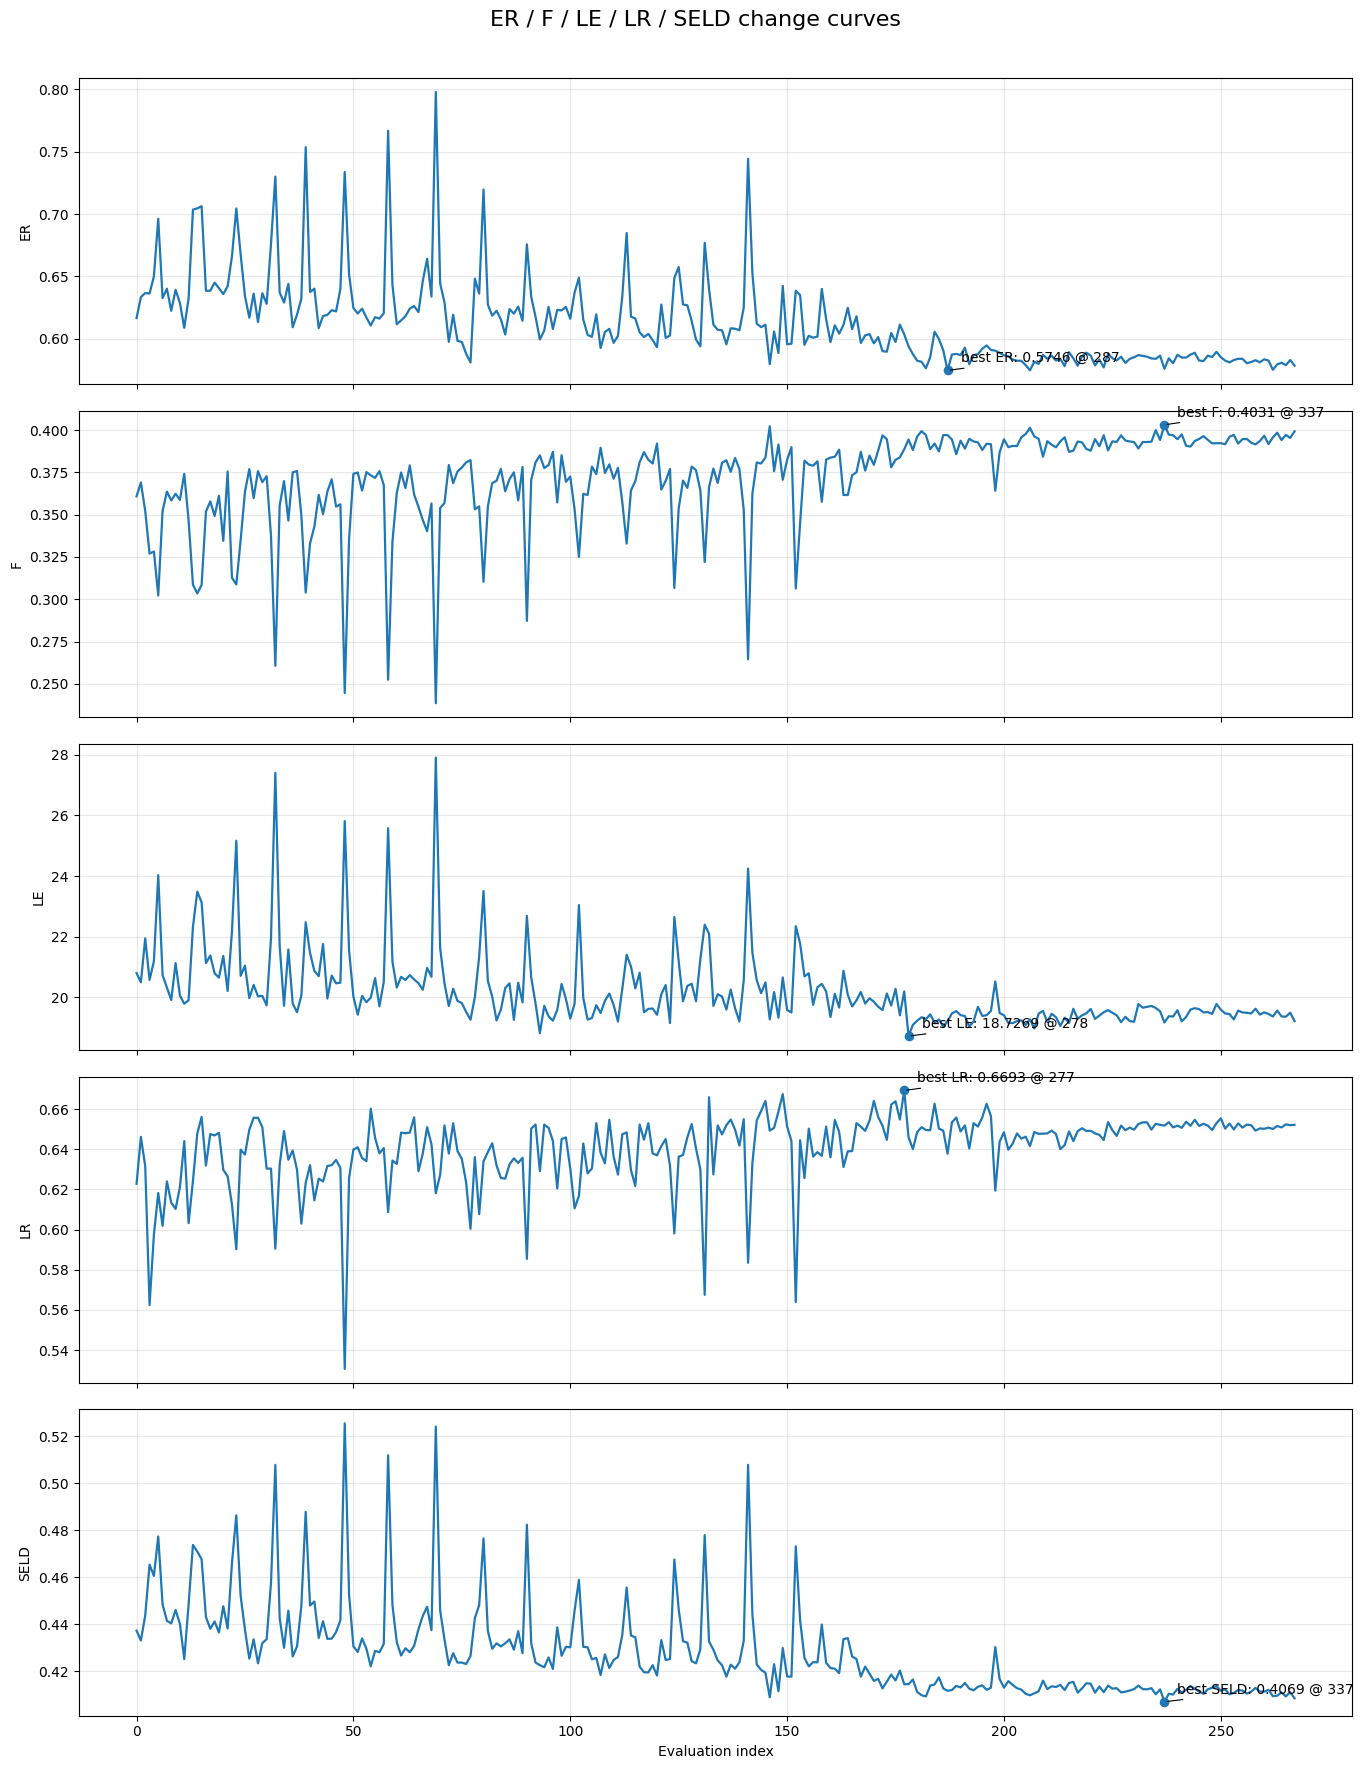

In [2]:
import re
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------
# 1) regex
# -------------------------------------------------
epoch_pattern = re.compile(r"epoch:\s*(\d+)")
metric_pattern = re.compile(
    r"ER/F/LE/LR/SELD:\s*"
    r"([0-9]+(?:\.[0-9]+)?)\s*/\s*"
    r"([0-9]+(?:\.[0-9]+)?)\s*/\s*"
    r"([0-9]+(?:\.[0-9]+)?)\s*/\s*"
    r"([0-9]+(?:\.[0-9]+)?)\s*/\s*"
    r"([0-9]+(?:\.[0-9]+)?)"
)

epochs = []
ER_list, F_list, LE_list, LR_list, SELD_list = [], [], [], [], []
current_epoch = None

for line in log_text.splitlines():
    epoch_match = epoch_pattern.search(line)
    if epoch_match:
        current_epoch = int(epoch_match.group(1))

    metric_match = metric_pattern.search(line)
    if metric_match and current_epoch is not None:
        er, f1, le, lr, seld = map(float, metric_match.groups())

        epochs.append(current_epoch)
        ER_list.append(er)
        F_list.append(f1)
        LE_list.append(le)
        LR_list.append(lr)
        SELD_list.append(seld)
        
# 3) plotting 함수
# -------------------------------------------------
def plot_metric_curves_like_example(epochs, ER, F, LE, LR, SELD, save_path=None):
    """
    x축은 evaluation index
    annotation은 best value와 epoch를 표시
    """

    # x축: evaluation index
    x = np.arange(len(epochs))

    fig, axes = plt.subplots(5, 1, figsize=(14, 18), sharex=True)
    fig.suptitle("ER / F / LE / LR / SELD change curves", fontsize=16)

    metric_configs = [
        ("ER", ER, "min"),
        ("F", F, "max"),
        ("LE", LE, "min"),
        ("LR", LR, "max"),
        ("SELD", SELD, "min"),
    ]

    for ax, (name, values, mode) in zip(axes, metric_configs):
        values = np.array(values, dtype=float)

        ax.plot(x, values, linewidth=1.6)
        ax.set_ylabel(name)
        ax.grid(True, alpha=0.3)

        # best index 찾기
        if mode == "min":
            best_idx = np.argmin(values)
        else:
            best_idx = np.argmax(values)

        best_x = x[best_idx]
        best_y = values[best_idx]
        best_epoch = epochs[best_idx]

        # best point 표시
        ax.scatter(best_x, best_y, s=35, zorder=3)

        # annotation 위치를 살짝 옆으로
        x_offset = max(3, len(x) * 0.01)
        y_span = values.max() - values.min()
        if y_span == 0:
            y_span = 1.0

        ax.annotate(
            f"best {name}: {best_y:.4f} @ {best_epoch}",
            xy=(best_x, best_y),
            xytext=(best_x + x_offset, best_y + y_span * 0.03),
            fontsize=10,
            arrowprops=dict(arrowstyle="-", lw=0.8)
        )

    axes[-1].set_xlabel("Evaluation index")
    plt.tight_layout(rect=[0, 0, 1, 0.97])

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()


# -------------------------------------------------
# 4) 실행
# -------------------------------------------------
plot_metric_curves_like_example(
    epochs=epochs,
    ER=ER_list,
    F=F_list,
    LE=LE_list,
    LR=LR_list,
    SELD=SELD_list,
    save_path="metric_curves.png"   # 저장 원하면 유지, 아니면 None
)